In [19]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the datasets
final_df = pd.read_csv('/content/final_combined.csv', index_col=0)
types_df = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')


In [23]:
types_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 955 entries, 0 to 954
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Player Name   955 non-null    object
 1   Bowling type  865 non-null    object
 2   Batting type  955 non-null    object
 3   Playing role  948 non-null    object
dtypes: object(4)
memory usage: 30.0+ KB


In [22]:
final_df.sample(10).to_csv()

',Inning_Number,Over.Ball,Batting_Team,Batsman,Non_Stricker,Bowler,Runs_off_Bat,Extras,Wides,No_Balls,Byes,Leg_Byes,Penalty,Kind_of_wicket_If_Any,Dissmissed_Player_When_Wicket,city,gender,date,toss_winner,toss_decision,venue,match_id\n90,1,13.6,Hong Kong,M Hill,KK Gill,Inyeong Oh,0,0,,,,,,,,Incheon,female,2014/09/22,Hong Kong,bat,Yeonhui Cricket Ground,it20s_csv/777999.csv\n107,1,16.7,England,CR Woakes,JM Vince,Mohammad Irfan,1,0,,,,,,,,,male,2015/11/30,England,bat,Sharjah Cricket Stadium,t20s_csv/902653.csv\n137,2,4.1,Saudi Arabia,Abdul Waheed,Imran Arif,Azmatullah Nazeer,1,0,,,,,,,,Kuwait City,male,2018/04/27,Kuwait,bat,Tack-Tec Ground,it20s_csv/1142223.csv\n68,1,10.7,Sri Lanka,DM de Silva,P Nissanka,MP Stoinis,1,0,,,,,,,,Perth,male,2022/10/25,Australia,field,Perth Stadium,t20s_csv/1298153.csv\n2,1,0.3,South Africa,Q de Kock,HM Amla,NM Coulter-Nile,4,0,,,,,,,,Cape Town,male,2016/03/09,South Africa,bat,Newlands,t20s_csv/884351.csv\n143,2,3.1,Malaysia,WA Duraisingam,Wan Julia,Madeeha Z

In [21]:
final_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 890379 entries, 0 to 256
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Inning_Number                  890379 non-null  int64  
 1   Over.Ball                      890379 non-null  float64
 2   Batting_Team                   890379 non-null  object 
 3   Batsman                        890379 non-null  object 
 4   Non_Stricker                   890379 non-null  object 
 5   Bowler                         890379 non-null  object 
 6   Runs_off_Bat                   890379 non-null  int64  
 7   Extras                         890379 non-null  int64  
 8   Wides                          36402 non-null   float64
 9   No_Balls                       4637 non-null    float64
 10  Byes                           3849 non-null    float64
 11  Leg_Byes                       11790 non-null   float64
 12  Penalty                        16 non-

In [ ]:
# Rename columns for clarity
final_df.rename(columns={
    'Batting type': 'Batsman_Batting_type',
    'Bowling type': 'Bowler_Bowling_type',
    'Playing role': 'Batsman_Playing_role'
}, inplace=True)


In [ ]:
final_df

,Inning_Number,Over.Ball,Batting_Team,Batsman,Non_Stricker,Bowler,Runs_off_Bat,Extras,Wides,No_Balls,...,date,toss_winner,toss_decision,venue,match_id,Batsman_Batting_type,Bowler_Bowling_type,Batsman_Playing_role,balls_faced,total_runs
0,1,0.1,Zimbabwe,CJ Chibhabha,H Masakadza,JD Unadkat,0,0,NaN,NaN,...,2016-06-18,India,field,Harare Sports Club,t20s_csv/1007655.csv,NaN,Left arm Medium,NaN,1,0
1,1,0.2,Zimbabwe,CJ Chibhabha,H Masakadza,JD Unadkat,0,0,NaN,NaN,...,2016-06-18,India,field,Harare Sports Club,t20s_csv/1007655.csv,NaN,Left arm Medium,NaN,2,0
2,1,0.3,Zimbabwe,CJ Chibhabha,H Masakadza,JD Unadkat,0,0,NaN,NaN,...,2016-06-18,India,field,Harare Sports Club,t20s_csv/1007655.csv,NaN,Left arm Medium,NaN,3,0
3,1,0.4,Zimbabwe,CJ Chibhabha,H Masakadza,JD Unadkat,1,0,NaN,NaN,...,2016-06-18,India,field,Harare Sports Club,t20s_csv/1007655.csv,NaN,Left arm Medium,NaN,4,1
4,1,0.5,Zimbabwe,H Masakadza,CJ Chibhabha,JD Unadkat,0,0,NaN,NaN,...,2016-06-18,India,field,Harare Sports Club,t20s_csv/1007655.csv,NaN,Left arm Medium,NaN,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,2,14.5,England,JM Bairstow,HC Brook,Naseem Shah,0,0,NaN,NaN,...,2024-05-30,England,field,"Kennington Oval, London",t20s_csv/1385690.csv,Right hand Bat,Right arm Fast,Wicketkeeper Batter,980,1374
215,2,14.6,England,JM Bairstow,HC Brook,Naseem Shah,0,0,NaN,NaN,...,2024-05-30,England,field,"Kennington Oval, London",t20s_csv/1385690.csv,Right hand Bat,Right arm Fast,Wicketkeeper Batter,981,1374
216,2,15.1,England,HC Brook,JM Bairstow,Haris Rauf,4,0,NaN,NaN,...,2024-05-30,England,field,"Kennington Oval, London",t20s_csv/1385690.csv,Right hand Bat,Right arm Fast,Batter,401,556
217,2,15.2,England,HC Brook,JM Bairstow,Haris Rauf,0,0,NaN,NaN,...,2024-05-30,England,field,"Kennington Oval, London",t20s_csv/1385690.csv,Right hand Bat,Right arm Fast,Batter,402,556


In [ ]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 337629 entries, 0 to 242
Data columns (total 31 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Inning_Number                  337629 non-null  int64         
 1   Over.Ball                      337629 non-null  float64       
 2   Batting_Team                   337629 non-null  object        
 3   Batsman                        337629 non-null  object        
 4   Non_Stricker                   337629 non-null  object        
 5   Bowler                         337629 non-null  object        
 6   Runs_off_Bat                   337629 non-null  int64         
 7   Extras                         337629 non-null  int64         
 8   Wides                          10782 non-null   float64       
 9   No_Balls                       1333 non-null    float64       
 10  Byes                           1054 non-null    float64       
 11  Leg_Byes

----


In [4]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby('Batsman')['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('/content/final_combined.csv', chunksize=chunk_size,index_col=0)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

print(processed_df.info())
print(processed_df.columns)
# print(processed_df.sample(10))

# After processing, perform additional feature engineering and prepare for model training
# Create target variables for the next match performance
processed_df['next_match_runs'] = processed_df.groupby('Batsman')['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby('Batsman')['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby('Batsman')['current_average'].shift(-1)

processed_df['next_match_economy_rate'] = processed_df.groupby('Bowler')['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby('Bowler')['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby('Bowler')['total_wickets'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data)
processed_df.dropna(subset=[
    'next_match_runs', 'next_match_strike_rate', 'next_match_average',
    'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'
], inplace=True)

# Feature Selection for Batsman
X_batsman = processed_df[['current_strike_rate', 'current_average']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']
print(X_batsman.info())

# Feature Selection for Bowler
X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']
print(X_bowler.info())
# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Initialize and train Random Forest models for each target variable
model_runs = RandomForestRegressor(n_estimators=100, random_state=42)
model_strike_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_average = RandomForestRegressor(n_estimators=100, random_state=42)

model_economy_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_wickets = RandomForestRegressor(n_estimators=100, random_state=42)
model_bowling_average = RandomForestRegressor(n_estimators=100, random_state=42)
import numpy as np


# Replace pd.NA with np.nan
X_train_batsman.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train the models with the imputed data
model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)

# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)



# Output the evaluation DataFrames for final assessment
batsman_evaluation_df, bowler_evaluation_df


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 890379 entries, 0 to 890378
Data columns (total 36 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Inning_Number                  890379 non-null  int64         
 1   Over.Ball                      890379 non-null  float64       
 2   Batting_Team                   890379 non-null  object        
 3   Batsman                        890379 non-null  object        
 4   Non_Stricker                   890379 non-null  object        
 5   Bowler                         890379 non-null  object        
 6   Runs_off_Bat                   890379 non-null  int64         
 7   Extras                         890379 non-null  int64         
 8   Wides                          890379 non-null  float64       
 9   No_Balls                       890379 non-null  float64       
 10  Byes                           890379 non-null  float64       
 11  

(        Metric        MAE         MSE        R²
 0         Runs  11.133809  562.752789  0.833407
 1  Strike Rate   3.615571   68.111343  0.958081
 2      Average   1.887815   27.056149  0.956249,
             Metric       MAE        MSE        R²
 0     Economy Rate  0.182901   0.150283  0.966347
 1          Wickets  0.694345   1.610108  0.786606
 2  Bowling Average  1.250692  11.710587  0.952973)

In [ ]:
from google.colab import files
files.download('/content/batsman_vs_bowler_stats.csv')
files.download('/content/bowler_vs_batsman_stats.csv')
files.download('/content/batsman_accuracy.csv')
files.download('/content/bowler_accuracy.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby('Batsman')['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('/content/final_combined.csv', chunksize=chunk_size)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# After processing, perform additional feature engineering and prepare for model training
# Create target variables for the next match performance
processed_df['next_match_runs'] = processed_df.groupby('Batsman')['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby('Batsman')['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby('Batsman')['current_average'].shift(-1)

processed_df['next_match_economy_rate'] = processed_df.groupby('Bowler')['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby('Bowler')['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby('Bowler')['total_wickets'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data)
processed_df.dropna(subset=[
    'next_match_runs', 'next_match_strike_rate', 'next_match_average',
    'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'
], inplace=True)

# Feature Selection for Batsman
X_batsman = processed_df[['current_strike_rate', 'current_average']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

# Feature Selection for Bowler
X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Replace pd.NA with np.nan
X_train_batsman.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Initialize and train XGBoost models for each target variable
model_runs = XGBRegressor(n_estimators=100, random_state=42)
model_strike_rate = XGBRegressor(n_estimators=100, random_state=42)
model_average = XGBRegressor(n_estimators=100, random_state=42)

model_economy_rate = XGBRegressor(n_estimators=100, random_state=42)
model_wickets = XGBRegressor(n_estimators=100, random_state=42)
model_bowling_average = XGBRegressor(n_estimators=100, random_state=42)

# Train the models with the imputed data
model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)



In [ ]:
# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)

# Output the evaluation DataFrames for final assessment
print("Batsman Model Evaluation:")
print(batsman_evaluation_df)

print("\nBowler Model Evaluation:")
print(bowler_evaluation_df)


Batsman Model Evaluation:
        Metric        MAE          MSE        R²
0         Runs  23.987745  1473.024738  0.563938
1  Strike Rate   3.570483    68.886690  0.957604
2      Average   1.871955    28.976487  0.953144

Bowler Model Evaluation:
            Metric       MAE        MSE        R²
0     Economy Rate  0.179266   0.153314  0.965668
1          Wickets  1.431151   4.269627  0.434128
2  Bowling Average  1.242538  13.043421  0.947621


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Calculate cumulative stats for batsman-bowler combinations
    chunk['balls_faced_pair'] = chunk.groupby(['Batsman', 'Bowler']).cumcount() + 1
    chunk['total_runs_pair'] = chunk.groupby(['Batsman', 'Bowler'])['Runs_off_Bat'].cumsum()

    chunk['dismissals_pair'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals_pair'] = chunk.groupby(['Batsman', 'Bowler'])['dismissals_pair'].cumsum()

    # Calculate metrics specific to batsman-bowler pair
    chunk['current_strike_rate_pair'] = (chunk['total_runs_pair'] / chunk['balls_faced_pair']) * 100
    chunk['current_average_pair'] = chunk['total_runs_pair'] / chunk['cumulative_dismissals_pair'].replace(0, pd.NA)

    # Calculate cumulative stats for bowlers against specific batsmen
    chunk['balls_bowled_pair'] = chunk.groupby(['Bowler', 'Batsman']).cumcount() + 1
    chunk['total_runs_conceded_pair'] = chunk.groupby(['Bowler', 'Batsman'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets_pair'] = chunk.groupby(['Bowler', 'Batsman'])['dismissals_pair'].cumsum()

    # Calculate metrics specific to bowler-batsman pair
    chunk['current_economy_rate_pair'] = (chunk['total_runs_conceded_pair'] / chunk['balls_bowled_pair']) * 6
    chunk['current_bowling_average_pair'] = chunk['total_runs_conceded_pair'] / chunk['total_wickets_pair'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('final_combined.csv', chunksize=chunk_size)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# After processing, perform additional feature engineering and prepare for model training
# Create target variables for the next match performance against specific bowlers/batsmen
processed_df['next_match_runs_pair'] = processed_df.groupby(['Batsman', 'Bowler'])['total_runs_pair'].shift(-1)
processed_df['next_match_strike_rate_pair'] = processed_df.groupby(['Batsman', 'Bowler'])['current_strike_rate_pair'].shift(-1)
processed_df['next_match_average_pair'] = processed_df.groupby(['Batsman', 'Bowler'])['current_average_pair'].shift(-1)

processed_df['next_match_economy_rate_pair'] = processed_df.groupby(['Bowler', 'Batsman'])['current_economy_rate_pair'].shift(-1)
processed_df['next_match_average_bowling_pair'] = processed_df.groupby(['Bowler', 'Batsman'])['current_bowling_average_pair'].shift(-1)
processed_df['next_match_wickets_pair'] = processed_df.groupby(['Bowler', 'Batsman'])['total_wickets_pair'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data)
processed_df.dropna(subset=[
    'next_match_runs_pair', 'next_match_strike_rate_pair', 'next_match_average_pair',
    'next_match_economy_rate_pair', 'next_match_average_bowling_pair', 'next_match_wickets_pair'
], inplace=True)

# Feature Selection for Batsman against specific Bowler
X_batsman_pair = processed_df[['current_strike_rate_pair', 'current_average_pair']]
y_runs_pair = processed_df['next_match_runs_pair']
y_strike_rate_pair = processed_df['next_match_strike_rate_pair']
y_average_pair = processed_df['next_match_average_pair']

# Feature Selection for Bowler against specific Batsman
X_bowler_pair = processed_df[['current_economy_rate_pair', 'current_bowling_average_pair']]
y_economy_rate_pair = processed_df['next_match_economy_rate_pair']
y_wickets_pair = processed_df['next_match_wickets_pair']
y_bowling_average_pair = processed_df['next_match_average_bowling_pair']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman_pair, X_test_batsman_pair, y_train_runs_pair, y_test_runs_pair = train_test_split(X_batsman_pair, y_runs_pair, test_size=0.2, random_state=42)
_, _, y_train_strike_rate_pair, y_test_strike_rate_pair = train_test_split(X_batsman_pair, y_strike_rate_pair, test_size=0.2, random_state=42)
_, _, y_train_average_pair, y_test_average_pair = train_test_split(X_batsman_pair, y_average_pair, test_size=0.2, random_state=42)

X_train_bowler_pair, X_test_bowler_pair, y_train_economy_rate_pair, y_test_economy_rate_pair = train_test_split(X_bowler_pair, y_economy_rate_pair, test_size=0.2, random_state=42)
_, _, y_train_wickets_pair, y_test_wickets_pair = train_test_split(X_bowler_pair, y_wickets_pair, test_size=0.2, random_state=42)
_, _, y_train_bowling_average_pair, y_test_bowling_average_pair = train_test_split(X_bowler_pair, y_bowling_average_pair, test_size=0.2, random_state=42)

# Replace pd.NA with np.nan
X_train_batsman_pair.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman_pair.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler_pair.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler_pair.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_pair_imputed = imputer.fit_transform(X_train_batsman_pair)
X_test_batsman_pair_imputed = imputer.transform(X_test_batsman_pair)

X_train_bowler_pair_imputed = imputer.fit_transform(X_train_bowler_pair)
X_test_bowler_pair_imputed = imputer.transform(X_test_bowler_pair)

# Initialize and train Random Forest models for each target variable
model_runs_pair = RandomForestRegressor(n_estimators=100, random_state=42)
model_strike_rate_pair = RandomForestRegressor(n_estimators=100, random_state=42)
model_average_pair = RandomForestRegressor(n_estimators=100, random_state=42)

model_economy_rate_pair = RandomForestRegressor(n_estimators=100, random_state=42)
model_wickets_pair = RandomForestRegressor(n_estimators=100, random_state=42)
model_bowling_average_pair = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the models with the imputed data
model_runs_pair.fit(X_train_batsman_pair_imputed, y_train_runs_pair)
model_strike_rate_pair.fit(X_train_batsman_pair_imputed, y_train_strike_rate_pair)
model_average_pair.fit(X_train_batsman_pair_imputed, y_train_average_pair)

model_economy_rate_pair.fit(X_train_bowler_pair_imputed, y_train_economy_rate_pair)
model_wickets_pair.fit(X_train_bowler_pair_imputed, y_train_wickets_pair)
model_bowling_average_pair.fit(X_train_bowler_pair_imputed, y_train_bowling_average_pair)

# Predict on the test set
y_pred_runs_pair = model_runs_pair.predict(X_test_batsman_pair_imputed)
y_pred_strike_rate_pair = model_strike_rate_pair.predict(X_test_batsman_pair_imputed)
y_pred_average_pair = model_average_pair.predict(X_test_batsman_pair_imputed)

y_pred_economy_rate_pair = model_economy_rate_pair.predict(X_test_bowler_pair_imputed)
y_pred_wickets_pair = model_wickets_pair.predict(X_test_bowler_pair_imputed)
y_pred_bowling_average_pair = model_bowling_average_pair.predict(X_test_bowler_pair_imputed)

# Evaluate the models for batsman performance against specific bowlers
mae_runs_pair = mean_absolute_error(y_test_runs_pair, y_pred_runs_pair)
mse_runs_pair = mean_squared_error(y_test_runs_pair, y_pred_runs_pair)
r2_runs_pair = r2_score(y_test_runs_pair, y_pred_runs_pair)

mae_strike_rate_pair = mean_absolute_error(y_test_strike_rate_pair, y_pred_strike_rate_pair)
mse_strike_rate_pair = mean_squared_error(y_test_strike_rate_pair, y_pred_strike_rate_pair)
r2_strike_rate_pair = r2_score(y_test_strike_rate_pair, y_pred_strike_rate_pair)

mae_average_pair = mean_absolute_error(y_test_average_pair, y_pred_average_pair)
mse_average_pair = mean_squared_error(y_test_average_pair, y_pred_average_pair)
r2_average_pair = r2_score(y_test_average_pair, y_pred_average_pair)

# Compile the evaluation results for batsman-bowler pairs
batsman_bowler_evaluation = {
    "Metric": ["Runs against Bowler", "Strike Rate against Bowler", "Average against Bowler"],
    "MAE": [mae_runs_pair, mae_strike_rate_pair, mae_average_pair],
    "MSE": [mse_runs_pair, mse_strike_rate_pair, mse_average_pair],
    "R²": [r2_runs_pair, r2_strike_rate_pair, r2_average_pair]
}
batsman_bowler_evaluation_df = pd.DataFrame(batsman_bowler_evaluation)

# Evaluate the models for bowler performance against specific batsmen
mae_economy_rate_pair = mean_absolute_error(y_test_economy_rate_pair, y_pred_economy_rate_pair)
mse_economy_rate_pair = mean_squared_error(y_test_economy_rate_pair, y_pred_economy_rate_pair)
r2_economy_rate_pair = r2_score(y_test_economy_rate_pair, y_pred_economy_rate_pair)

mae_wickets_pair = mean_absolute_error(y_test_wickets_pair, y_pred_wickets_pair)
mse_wickets_pair = mean_squared_error(y_test_wickets_pair, y_pred_wickets_pair)
r2_wickets_pair = r2_score(y_test_wickets_pair, y_pred_wickets_pair)

mae_bowling_average_pair = mean_absolute_error(y_test_bowling_average_pair, y_pred_bowling_average_pair)
mse_bowling_average_pair = mean_squared_error(y_test_bowling_average_pair, y_pred_bowling_average_pair)
r2_bowling_average_pair = r2_score(y_test_bowling_average_pair, y_pred_bowling_average_pair)

# Compile the evaluation results for bowler-batsman pairs
bowler_batsman_evaluation = {
    "Metric": ["Economy Rate against Batsman", "Wickets against Batsman", "Bowling Average against Batsman"],
    "MAE": [mae_economy_rate_pair, mae_wickets_pair, mae_bowling_average_pair],
    "MSE": [mse_economy_rate_pair, mse_wickets_pair, mse_bowling_average_pair],
    "R²": [r2_economy_rate_pair, r2_wickets_pair, r2_bowling_average_pair]
}
bowler_batsman_evaluation_df = pd.DataFrame(bowler_batsman_evaluation)

# Output the evaluation DataFrames for final assessment
batsman_bowler_evaluation_df, bowler_batsman_evaluation_df



(                       Metric        MAE         MSE        R²
 0         Runs against Bowler   1.363183    6.578529  0.906581
 1  Strike Rate against Bowler  11.915632  515.664451  0.867513
 2      Average against Bowler   1.362154    6.475645  0.896877,
                             Metric       MAE       MSE        R²
 0     Economy Rate against Batsman  0.714952  1.856439  0.867509
 1          Wickets against Batsman  0.077677  0.042137  0.423385
 2  Bowling Average against Batsman  1.362138  6.475637  0.896878)

In [7]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Determine the Bowling Team
    chunk['Bowling_Team'] = chunk.apply(lambda row: row['Batting_Team']
                                        if row['Inning_Number'] % 2 == 0
                                        else chunk['Batting_Team'].shift(-1).iloc[0], axis=1)

    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby('Batsman')['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('/content/final_combined.csv', chunksize=chunk_size, index_col=0)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# Feature Engineering: Calculate features based on past performance against specific teams
processed_df['past_runs_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['total_runs'].shift(1)
processed_df['past_strike_rate_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_strike_rate'].shift(1)
processed_df['past_average_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_average'].shift(1)

processed_df['past_economy_rate_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_economy_rate'].shift(1)
processed_df['past_wickets_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['total_wickets'].shift(1)
processed_df['past_bowling_average_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_bowling_average'].shift(1)

# Drop rows where the past performance data is NaN
processed_df.dropna(subset=[
    'past_runs_against_team', 'past_strike_rate_against_team', 'past_average_against_team',
    'past_economy_rate_against_team', 'past_wickets_against_team', 'past_bowling_average_against_team'
], inplace=True)

# Create the target variables (next match performance against the same team)
processed_df['next_match_runs_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_average'].shift(-1)

processed_df['next_match_economy_rate_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_wickets_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['total_wickets'].shift(-1)
processed_df['next_match_bowling_average_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_bowling_average'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data against the same team)
processed_df.dropna(subset=[
    'next_match_runs_against_team', 'next_match_strike_rate_against_team', 'next_match_average_against_team',
    'next_match_economy_rate_against_team', 'next_match_wickets_against_team', 'next_match_bowling_average_against_team'
], inplace=True)

# Feature Selection for Batsman
X_batsman = processed_df[['past_strike_rate_against_team', 'past_average_against_team']]
y_runs = processed_df['next_match_runs_against_team']
y_strike_rate = processed_df['next_match_strike_rate_against_team']
y_average = processed_df['next_match_average_against_team']

# Feature Selection for Bowler
X_bowler = processed_df[['past_economy_rate_against_team', 'past_bowling_average_against_team']]
y_economy_rate = processed_df['next_match_economy_rate_against_team']
y_wickets = processed_df['next_match_wickets_against_team']
y_bowling_average = processed_df['next_match_bowling_average_against_team']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Initialize and train Random Forest models for each target variable
model_runs = RandomForestRegressor(n_estimators=100, random_state=42)
model_strike_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_average = RandomForestRegressor(n_estimators=100, random_state=42)

model_economy_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_wickets = RandomForestRegressor(n_estimators=100, random_state=42)
model_bowling_average = RandomForestRegressor(n_estimators=100, random_state=42)

# Replace pd.NA with np.nan
X_train_batsman.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train the models with the imputed data
model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)

# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)

# Output the evaluation DataFrames for final assessment
batsman_evaluation_df, bowler_evaluation_df


(        Metric        MAE         MSE        R²
 0         Runs  13.830995  773.246886  0.779008
 1  Strike Rate   6.524985  166.381467  0.888603
 2      Average   3.285401   59.368907  0.904987,
             Metric       MAE        MSE        R²
 0     Economy Rate  0.336484   0.414408  0.898899
 1          Wickets  0.846719   2.174720  0.718972
 2  Bowling Average  2.207511  27.258021  0.890034)

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Determine the Bowling Team
    chunk['Bowling_Team'] = chunk.apply(lambda row: row['Batting_Team']
                                        if row['Inning_Number'] % 2 == 0
                                        else chunk['Batting_Team'].shift(-1).iloc[0], axis=1)

    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby('Batsman')['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    # Additional Features: Player form in the last 5 matches
    chunk['player_form_runs_last_5_matches'] = chunk.groupby('Batsman')['total_runs'].rolling(window=5, min_periods=1).mean().reset_index(drop=True)
    chunk['player_form_wickets_last_5_matches'] = chunk.groupby('Bowler')['total_wickets'].rolling(window=5, min_periods=1).sum().reset_index(drop=True)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('/content/final_combined.csv', chunksize=chunk_size, index_col=0)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# Calculate the average runs scored by each batsman against all teams
processed_df['average_runs_against_all_teams'] = processed_df.groupby('Batsman')['total_runs'].expanding().mean().reset_index(level=0, drop=True)

# Calculate the average wickets taken by each bowler against all teams
processed_df['average_wickets_against_all_teams'] = processed_df.groupby('Bowler')['total_wickets'].expanding().mean().reset_index(level=0, drop=True)

# Feature Engineering: Calculate features based on past performance against specific teams
processed_df['past_runs_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['total_runs'].shift(1)
processed_df['past_strike_rate_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_strike_rate'].shift(1)
processed_df['past_average_against_team'] = processed_df.groupby(['Batsman', 'Bowling_Team'])['current_average'].shift(1)

processed_df['past_economy_rate_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_economy_rate'].shift(1)
processed_df['past_wickets_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['total_wickets'].shift(1)
processed_df['past_bowling_average_against_team'] = processed_df.groupby(['Bowler', 'Batting_Team'])['current_bowling_average'].shift(1)

# Drop rows where the past performance data is NaN
processed_df.dropna(subset=[
    'past_runs_against_team', 'past_strike_rate_against_team', 'past_average_against_team',
    'past_economy_rate_against_team', 'past_wickets_against_team', 'past_bowling_average_against_team'
], inplace=True)

# Optimized method for getting the next match performance
def get_next_match_performance_optimized(df, player_column, team_column, target_column):
    df = df.sort_values(by=['date']).reset_index(drop=True)
    df['next_match_' + target_column] = df.groupby([player_column, team_column])[target_column].shift(-1)
    return df['next_match_' + target_column]

# Apply the optimized function to get the next match performance against the same team
processed_df['next_match_runs_against_team'] = get_next_match_performance_optimized(processed_df, 'Batsman', 'Bowling_Team', 'total_runs')
processed_df['next_match_strike_rate_against_team'] = get_next_match_performance_optimized(processed_df, 'Batsman', 'Bowling_Team', 'current_strike_rate')
processed_df['next_match_average_against_team'] = get_next_match_performance_optimized(processed_df, 'Batsman', 'Bowling_Team', 'current_average')

processed_df['next_match_economy_rate_against_team'] = get_next_match_performance_optimized(processed_df, 'Bowler', 'Batting_Team', 'current_economy_rate')
processed_df['next_match_wickets_against_team'] = get_next_match_performance_optimized(processed_df, 'Bowler', 'Batting_Team', 'total_wickets')
processed_df['next_match_bowling_average_against_team'] = get_next_match_performance_optimized(processed_df, 'Bowler', 'Batting_Team', 'current_bowling_average')

# Drop rows where the target variables are NaN (i.e., no next match data against the same team)
processed_df.dropna(subset=[
    'next_match_runs_against_team', 'next_match_strike_rate_against_team', 'next_match_average_against_team',
    'next_match_economy_rate_against_team', 'next_match_wickets_against_team', 'next_match_bowling_average_against_team'
], inplace=True)

# Feature Selection for Batsman (including additional features)
X_batsman = processed_df[['past_strike_rate_against_team', 'past_average_against_team', 'venue', 'city', 'toss_decision', 'toss_winner', 'Inning_Number',
                          'player_form_runs_last_5_matches', 'average_runs_against_all_teams', 'Batting type', 'Playing role']]
y_runs = processed_df['next_match_runs_against_team']
y_strike_rate = processed_df['next_match_strike_rate_against_team']
y_average = processed_df['next_match_average_against_team']

# Feature Selection for Bowler (including additional features)
X_bowler = processed_df[['past_economy_rate_against_team', 'past_bowling_average_against_team', 'venue', 'city', 'toss_decision', 'toss_winner', 'Inning_Number',
                         'player_form_wickets_last_5_matches', 'average_wickets_against_all_teams', 'Bowling type', 'Playing role']]
y_economy_rate = processed_df['next_match_economy_rate_against_team']
y_wickets = processed_df['next_match_wickets_against_team']
y_bowling_average = processed_df['next_match_bowling_average_against_team']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Separate the features into numeric and categorical
numeric_features_batsman = ['past_strike_rate_against_team', 'past_average_against_team',
                             'player_form_runs_last_5_matches', 'average_runs_against_all_teams']
categorical_features_batsman = ['venue', 'city', 'toss_decision', 'toss_winner', 'Inning_Number', 'Batting type', 'Playing role']

numeric_features_bowler = ['past_economy_rate_against_team', 'past_bowling_average_against_team',
                            'player_form_wickets_last_5_matches', 'average_wickets_against_all_teams']
categorical_features_bowler = ['venue', 'city', 'toss_decision', 'toss_winner', 'Inning_Number', 'Bowling type', 'Playing role']

# Preprocessing pipelines for numeric and categorical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Combine numeric and categorical transformers
preprocessor_batsman = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features_batsman),
        ('cat', categorical_transformer, categorical_features_batsman)])

preprocessor_bowler = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features_bowler),
        ('cat', categorical_transformer, categorical_features_bowler)])

# Apply preprocessing to batsman features
X_train_batsman = preprocessor_batsman.fit_transform(X_train_batsman)
X_test_batsman = preprocessor_batsman.transform(X_test_batsman)

# Apply preprocessing to bowler features
X_train_bowler = preprocessor_bowler.fit_transform(X_train_bowler)
X_test_bowler = preprocessor_bowler.transform(X_test_bowler)

# Initialize and train XGBoost models for each target variable with GPU support
params = {
    'n_estimators': 100,
    'learning_rate': 0.1,
    'max_depth': 6,
    'tree_method': 'hist',  # Use histogram-based algorithm
    'device': 'cuda',  # Use GPU
    'random_state': 42
}

model_runs = xgb.XGBRegressor(**params)
model_strike_rate = xgb.XGBRegressor(**params)
model_average = xgb.XGBRegressor(**params)

model_economy_rate = xgb.XGBRegressor(**params)
model_wickets = xgb.XGBRegressor(**params)
model_bowling_average = xgb.XGBRegressor(**params)

# Train the models with the preprocessed data
model_runs.fit(X_train_batsman, y_train_runs)
model_strike_rate.fit(X_train_batsman, y_train_strike_rate)
model_average.fit(X_train_batsman, y_train_average)

model_economy_rate.fit(X_train_bowler, y_train_economy_rate)
model_wickets.fit(X_train_bowler, y_train_wickets)
model_bowling_average.fit(X_train_bowler, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman)
y_pred_average = model_average.predict(X_test_batsman)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler)
y_pred_wickets = model_wickets.predict(X_test_bowler)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler)

# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)

# Output the evaluation DataFrames for final assessment
batsman_evaluation_df, bowler_evaluation_df


(        Metric        MAE          MSE        R²
 0         Runs  40.643855  2978.387519  0.137103
 1  Strike Rate  28.096769  1299.249159  0.135166
 2      Average  17.231484   553.142950  0.099774,
             Metric        MAE         MSE        R²
 0     Economy Rate   1.452881    3.456905  0.157456
 1          Wickets   2.001926    6.943483  0.118595
 2  Bowling Average  10.610907  223.909144  0.070674)

In [18]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('/content/Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Create Bowling_Team column based on Inning_Number
        # Create Bowling_Team column based on Inning_Number
    chunk['Bowling_Team'] = chunk.apply(
        lambda row: row['Batting_Team'] if row['Inning_Number'] % 2 == 0
        else chunk['Batting_Team'].shift(-1).iloc[0], axis=1)
    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('/content/final_combined.csv', chunksize=chunk_size, index_col=0)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# After processing, perform additional feature engineering and prepare for model training
# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)

processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data)
processed_df.dropna(subset=[
    'next_match_runs', 'next_match_strike_rate', 'next_match_average',
    'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'
], inplace=True)

# Feature Selection for Batsman
X_batsman = processed_df[['current_strike_rate', 'current_average']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

# Feature Selection for Bowler
X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Initialize and train Random Forest models for each target variable
model_runs = RandomForestRegressor(n_estimators=100, random_state=42)
model_strike_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_average = RandomForestRegressor(n_estimators=100, random_state=42)

model_economy_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_wickets = RandomForestRegressor(n_estimators=100, random_state=42)
model_bowling_average = RandomForestRegressor(n_estimators=100, random_state=42)

# Replace pd.NA with np.nan
X_train_batsman.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train the models with the imputed data
model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)

# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)

# Output the evaluation DataFrames for final assessment
batsman_evaluation_df, bowler_evaluation_df


(        Metric        MAE         MSE        R²
 0         Runs  11.556686  618.969027  0.814152
 1  Strike Rate   3.818658   79.133513  0.952245
 2      Average   2.099727   30.036704  0.950205,
             Metric       MAE        MSE        R²
 0     Economy Rate  0.287166   0.318071  0.947143
 1          Wickets  0.464760   0.706704  0.781437
 2  Bowling Average  1.392617  11.542853  0.944673)

In [5]:
from sklearn.impute import SimpleImputer

# Impute missing values in the test sets for both scenarios
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Scenario 1: Test data based on the last match of the client team against any opponent
X_test_batsman_scenario_1, X_test_bowler_scenario_1 = create_scenario_1_test_set(processed_df, client_team)
X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_bowler_scenario_1_imputed = impute_missing_values(X_test_bowler_scenario_1)

# Scenario 2: Test data based on the last match of the client team against the specified opponent
X_test_batsman_scenario_2, X_test_bowler_scenario_2 = create_scenario_2_test_set(processed_df, client_team, opponent_team)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)
X_test_bowler_scenario_2_imputed = impute_missing_values(X_test_bowler_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

y_pred_economy_rate_scenario_1 = model_economy_rate.predict(X_test_bowler_scenario_1_imputed)
y_pred_wickets_scenario_1 = model_wickets.predict(X_test_bowler_scenario_1_imputed)
y_pred_bowling_average_scenario_1 = model_bowling_average.predict(X_test_bowler_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

y_pred_economy_rate_scenario_2 = model_economy_rate.predict(X_test_bowler_scenario_2_imputed)
y_pred_wickets_scenario_2 = model_wickets.predict(X_test_bowler_scenario_2_imputed)
y_pred_bowling_average_scenario_2 = model_bowling_average.predict(X_test_bowler_scenario_2_imputed)

# Print Scenario 1 Results
print("Scenario 1 - Predictions Based on Last Match of Client Team Against Any Opponent:")
print(f"Predicted Runs: {y_pred_runs_scenario_1}")
print(f"Predicted Strike Rate: {y_pred_strike_rate_scenario_1}")
print(f"Predicted Average: {y_pred_average_scenario_1}")
print(f"Predicted Economy Rate: {y_pred_economy_rate_scenario_1}")
print(f"Predicted Wickets: {y_pred_wickets_scenario_1}")
print(f"Predicted Bowling Average: {y_pred_bowling_average_scenario_1}")

# Print Scenario 2 Results
print("Scenario 2 - Predictions Based on Last Match of Client Team Against Specified Opponent:")
print(f"Predicted Runs: {y_pred_runs_scenario_2}")
print(f"Predicted Strike Rate: {y_pred_strike_rate_scenario_2}")
print(f"Predicted Average: {y_pred_average_scenario_2}")
print(f"Predicted Economy Rate: {y_pred_economy_rate_scenario_2}")
print(f"Predicted Wickets: {y_pred_wickets_scenario_2}")
print(f"Predicted Bowling Average: {y_pred_bowling_average_scenario_2}")


Scenario 1 - Predictions Based on Last Match of Client Team Against Any Opponent:
Predicted Runs: [  1.85127127 120.76854762   0.50622499  33.45        15.90387985
  10.8973166   16.93372694   0.50622499 120.76854762  15.43923624
  13.94737592  33.45        33.45        33.06920012  66.36899603
  38.55733038   2.97532105  62.96462744 145.06930159  21.86518136
  23.19325634  64.31403092   9.62464023  19.20895913  42.21441763
  88.97528581  61.99146414  26.07013747  39.57427609  15.59483107
  25.76902254   3.02647191   9.46213321 115.26044444  37.79638636
  23.57564693  29.20090962  39.99558357  29.89992315  27.76827993
   0.50622499   0.50622499  27.53131732  91.99560732  16.96846455
   2.97532105  24.00273902 152.945       10.21044004  33.45
  66.50936399  12.58933389  33.45        11.78613229  87.08665079
  43.12736905  27.84612859  33.45        38.59369662  26.38549603
  57.25256195  62.60661515  21.43022817   9.43495761  52.82453702
  59.51936015  90.29692094  12.04916814  66.147638

Scenario 1 Evaluation:
Runs - MAE: 56.80745813547616, MSE: 5873.808912209479, R²: -0.9333097911677184
Strike Rate - MAE: 46.13791747520583, MSE: 3416.196696231197, R²: -1.103589008647178
Average - MAE: 22.83672464970337, MSE: 1052.4644811950766, R²: -0.7949095439987119
Economy Rate - MAE: 2.7950871970455284, MSE: 12.76458305816153, R²: -1.1022048709472037
Wickets - MAE: 1.8282993950887332, MSE: 6.406008098256034, R²: -1.2004549508342195
Bowling Average - MAE: 14.881729589073604, MSE: 444.4786228475927, R²: -1.0548764282700764
Scenario 2 Evaluation:
Runs - MAE: 53.64458810300535, MSE: 5069.935978488508, R²: -2.4330560986380014
Strike Rate - MAE: 40.056628498037114, MSE: 2481.5059740632346, R²: -1.1567453924537685
Average - MAE: 25.91815973989937, MSE: 1144.8971184498735, R²: -1.3811538623022295
Economy Rate - MAE: 2.110911484592903, MSE: 6.82843946511113, R²: -0.44328265521458454
Wickets - MAE: 2.4738511247965658, MSE: 12.69124895853483, R²: -2.614469483369536
Bowling Average - MAE: 13.

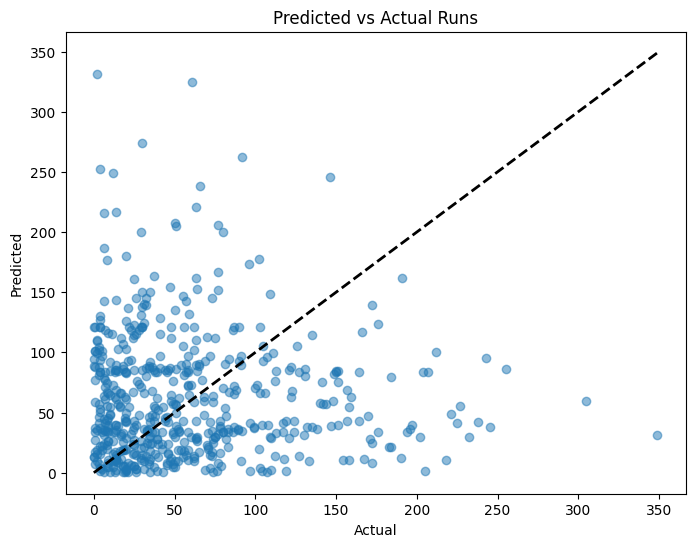

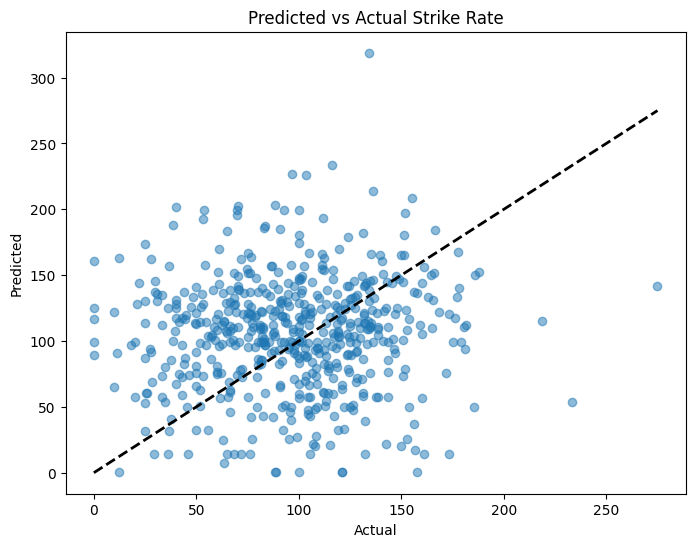

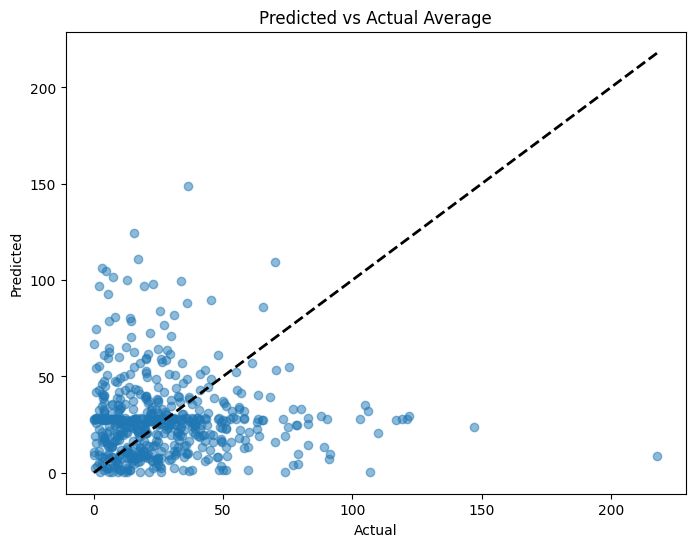

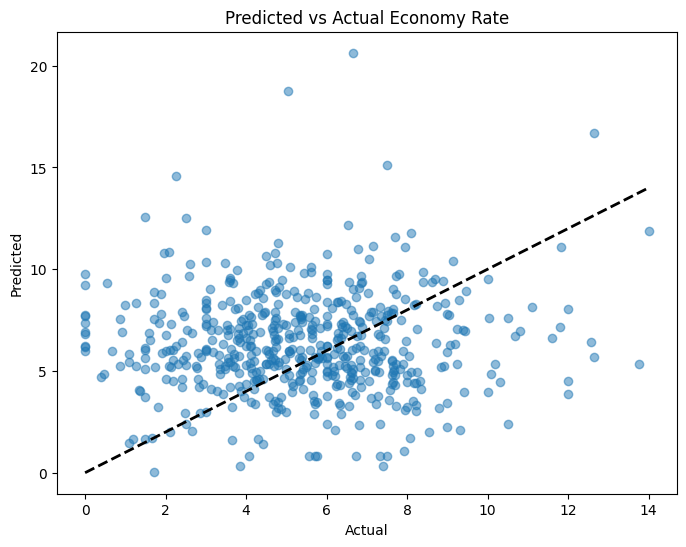

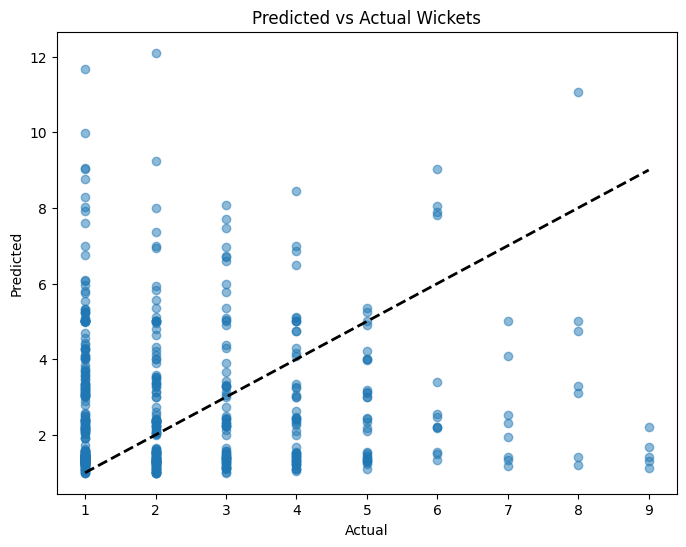

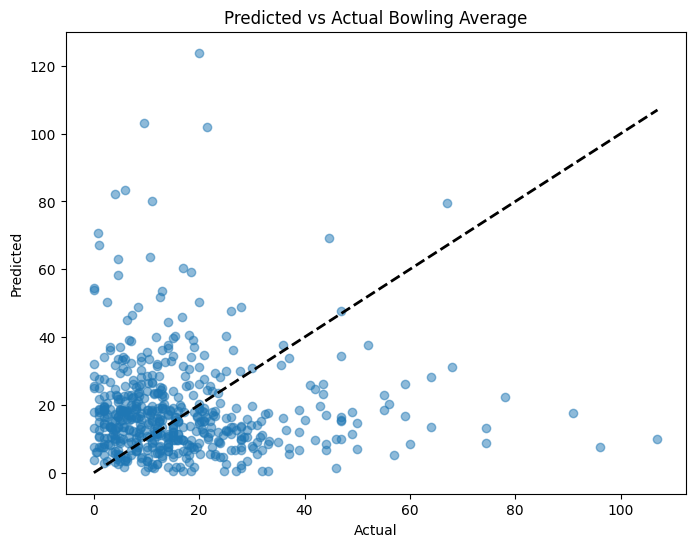

Scenario 2 - Predicted vs Actual Plots:


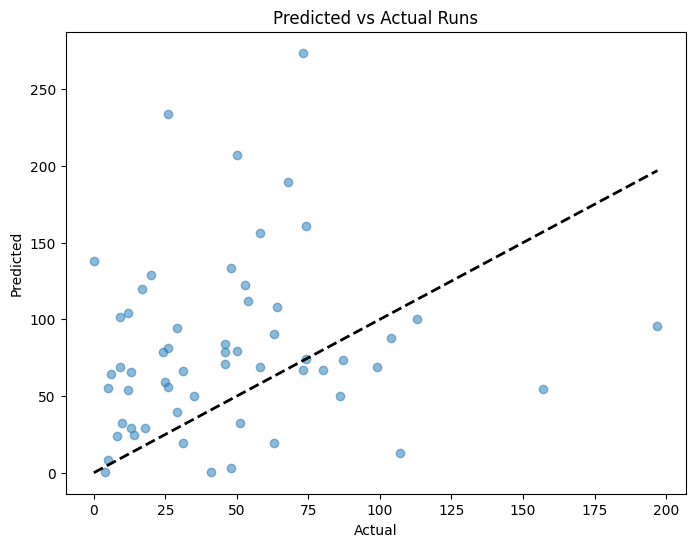

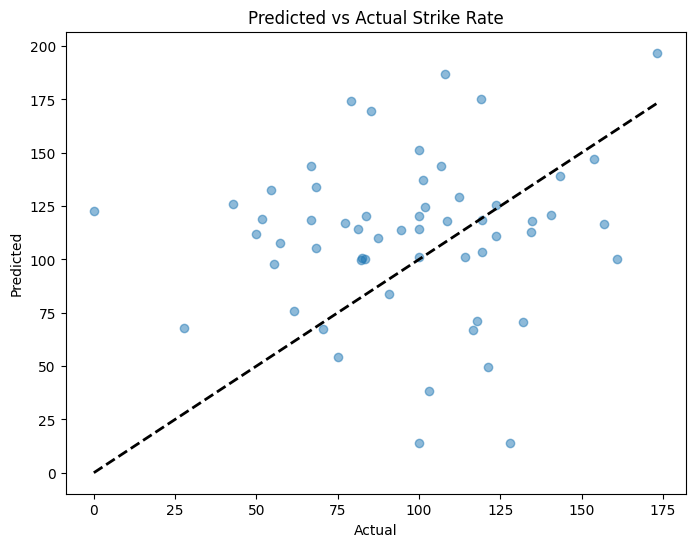

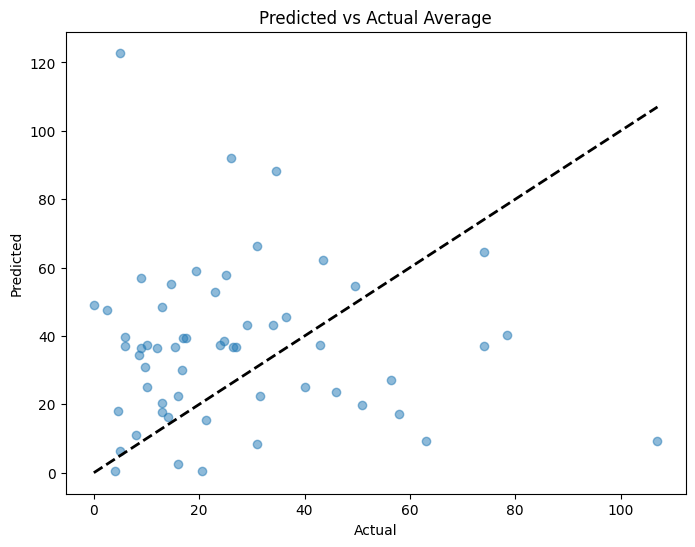

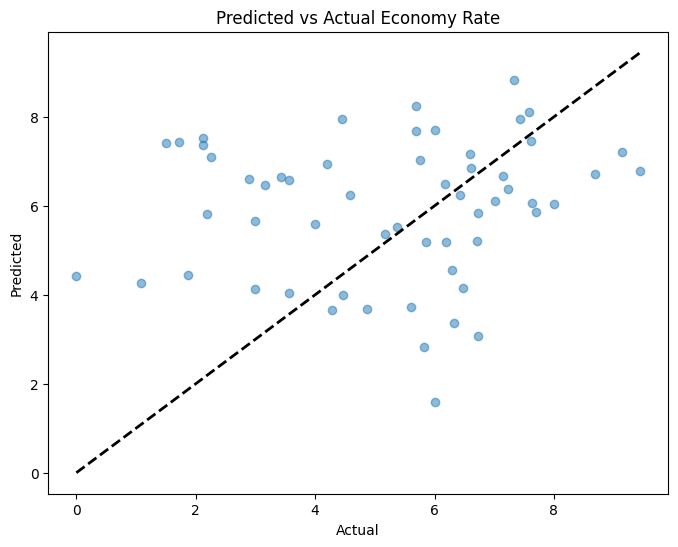

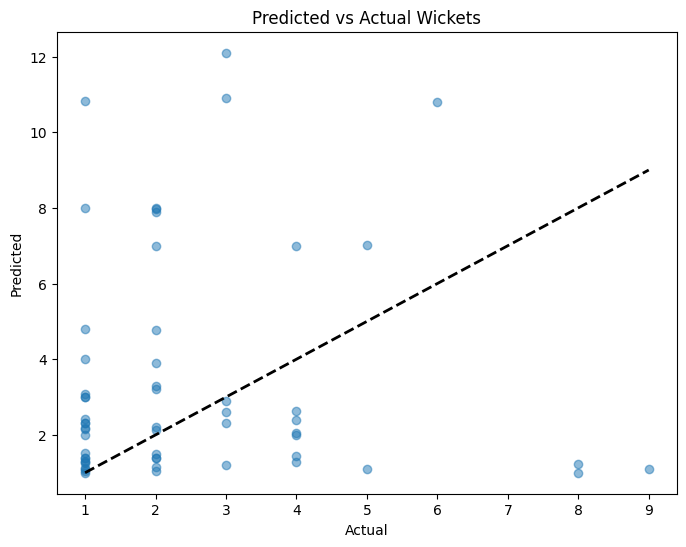

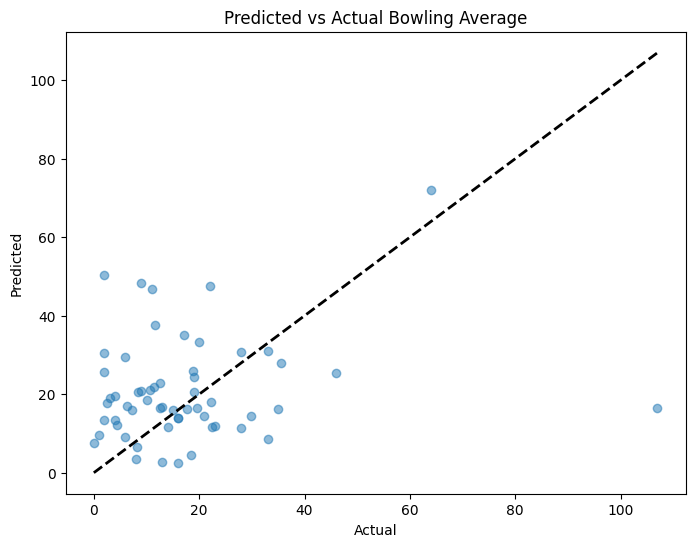

In [7]:
import matplotlib.pyplot as plt

# Function to ensure consistent length between actual and predicted values
def align_predictions(y_true, y_pred):
    min_len = min(len(y_true), len(y_pred))
    return y_true[:min_len], y_pred[:min_len]

# Define a function to calculate and print evaluation metrics
def evaluate_model(y_true, y_pred, metric_name):
    y_true, y_pred = align_predictions(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{metric_name} - MAE: {mae}, MSE: {mse}, R²: {r2}")
    return mae, mse, r2

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate_model(y_test_runs, y_pred_runs_scenario_1, "Runs")
evaluate_model(y_test_strike_rate, y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate_model(y_test_average, y_pred_average_scenario_1, "Average")
evaluate_model(y_test_economy_rate, y_pred_economy_rate_scenario_1, "Economy Rate")
evaluate_model(y_test_wickets, y_pred_wickets_scenario_1, "Wickets")
evaluate_model(y_test_bowling_average, y_pred_bowling_average_scenario_1, "Bowling Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
evaluate_model(y_test_runs, y_pred_runs_scenario_2, "Runs")
evaluate_model(y_test_strike_rate, y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate_model(y_test_average, y_pred_average_scenario_2, "Average")
evaluate_model(y_test_economy_rate, y_pred_economy_rate_scenario_2, "Economy Rate")
evaluate_model(y_test_wickets, y_pred_wickets_scenario_2, "Wickets")
evaluate_model(y_test_bowling_average, y_pred_bowling_average_scenario_2, "Bowling Average")

# Plotting function for predicted vs actual values
def plot_predictions(y_true, y_pred, metric_name):
    y_true, y_pred = align_predictions(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {metric_name}')
    plt.show()

# Scenario 1 Plots
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(y_test_runs, y_pred_runs_scenario_1, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(y_test_average, y_pred_average_scenario_1, "Average")
plot_predictions(y_test_economy_rate, y_pred_economy_rate_scenario_1, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets_scenario_1, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average_scenario_1, "Bowling Average")

# Scenario 2 Plots
print("Scenario 2 - Predicted vs Actual Plots:")
plot_predictions(y_test_runs, y_pred_runs_scenario_2, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate_scenario_2, "Strike Rate")
plot_predictions(y_test_average, y_pred_average_scenario_2, "Average")
plot_predictions(y_test_economy_rate, y_pred_economy_rate_scenario_2, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets_scenario_2, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average_scenario_2, "Bowling Average")


---


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the additional player info dataset
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process each chunk
def process_chunk(chunk):
    # Convert date column to datetime format
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')

    # Handle missing values in a straightforward way
    chunk.fillna({
        'Wides': 0,
        'No_Balls': 0,
        'Byes': 0,
        'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out',
        'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    # Merge with player info data
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Ensure that the Batting_Team is correctly aligned with the Bowling_Team
    chunk['Bowling_Team'] = chunk['Batting_Team'].shift(-1)
    chunk.loc[chunk['Inning_Number'] % 2 == 0, 'Bowling_Team'] = chunk['Batting_Team']

    # Calculate simple cumulative sums for runs and balls faced
    chunk['balls_faced'] = chunk.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()

    # Calculate dismissals
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()

    # Calculate current Strike Rate and Average
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, pd.NA)

    # Calculate cumulative sums for bowlers
    chunk['balls_bowled'] = chunk.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()

    # Calculate current Economy Rate and Bowling Average
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, pd.NA)

    return chunk

# Initialize an empty DataFrame to store the processed data
processed_df = pd.DataFrame()

# Load the dataset in chunks and process each chunk
chunk_size = 10000  # Define the chunk size
chunks = pd.read_csv('final_combined.csv', chunksize=chunk_size, index_col=0)

for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# After processing, perform additional feature engineering and prepare for model training
# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)

processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows where the target variables are NaN (i.e., no next match data)
processed_df.dropna(subset=[
    'next_match_runs', 'next_match_strike_rate', 'next_match_average',
    'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'
], inplace=True)

# Feature Selection for Batsman
X_batsman = processed_df[['current_strike_rate', 'current_average']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

# Feature Selection for Bowler
X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Split the data into training and testing sets for both batsman and bowler models
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Initialize and train Random Forest models for each target variable
model_runs = RandomForestRegressor(n_estimators=100, random_state=42)
model_strike_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_average = RandomForestRegressor(n_estimators=100, random_state=42)

model_economy_rate = RandomForestRegressor(n_estimators=100, random_state=42)
model_wickets = RandomForestRegressor(n_estimators=100, random_state=42)
model_bowling_average = RandomForestRegressor(n_estimators=100, random_state=42)

# Replace pd.NA with np.nan
X_train_batsman.replace({pd.NA: np.nan}, inplace=True)
X_test_batsman.replace({pd.NA: np.nan}, inplace=True)

X_train_bowler.replace({pd.NA: np.nan}, inplace=True)
X_test_bowler.replace({pd.NA: np.nan}, inplace=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train the models with the imputed data
model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on the test set
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)

# Evaluate the models for batsman performance
mae_runs = mean_absolute_error(y_test_runs, y_pred_runs)
mse_runs = mean_squared_error(y_test_runs, y_pred_runs)
r2_runs = r2_score(y_test_runs, y_pred_runs)

mae_strike_rate = mean_absolute_error(y_test_strike_rate, y_pred_strike_rate)
mse_strike_rate = mean_squared_error(y_test_strike_rate, y_pred_strike_rate)
r2_strike_rate = r2_score(y_test_strike_rate, y_pred_strike_rate)

mae_average = mean_absolute_error(y_test_average, y_pred_average)
mse_average = mean_squared_error(y_test_average, y_pred_average)
r2_average = r2_score(y_test_average, y_pred_average)

# Compile the evaluation results for batsman
batsman_evaluation = {
    "Metric": ["Runs", "Strike Rate", "Average"],
    "MAE": [mae_runs, mae_strike_rate, mae_average],
    "MSE": [mse_runs, mse_strike_rate, mse_average],
    "R²": [r2_runs, r2_strike_rate, r2_average]
}
batsman_evaluation_df = pd.DataFrame(batsman_evaluation)

# Evaluate the models for bowler performance
mae_economy_rate = mean_absolute_error(y_test_economy_rate, y_pred_economy_rate)
mse_economy_rate = mean_squared_error(y_test_economy_rate, y_pred_economy_rate)
r2_economy_rate = r2_score(y_test_economy_rate, y_pred_economy_rate)

mae_wickets = mean_absolute_error(y_test_wickets, y_pred_wickets)
mse_wickets = mean_squared_error(y_test_wickets, y_pred_wickets)
r2_wickets = r2_score(y_test_wickets, y_pred_wickets)

mae_bowling_average = mean_absolute_error(y_test_bowling_average, y_pred_bowling_average)
mse_bowling_average = mean_squared_error(y_test_bowling_average, y_pred_bowling_average)
r2_bowling_average = r2_score(y_test_bowling_average, y_pred_bowling_average)

# Compile the evaluation results for bowler
bowler_evaluation = {
    "Metric": ["Economy Rate", "Wickets", "Bowling Average"],
    "MAE": [mae_economy_rate, mae_wickets, mae_bowling_average],
    "MSE": [mse_economy_rate, mse_wickets, mse_bowling_average],
    "R²": [r2_economy_rate, r2_wickets, r2_bowling_average]
}
bowler_evaluation_df = pd.DataFrame(bowler_evaluation)

# Output the evaluation DataFrames for final assessment
batsman_evaluation_df, bowler_evaluation_df

# Now evaluate the two scenarios
from sklearn.impute import SimpleImputer

# Impute missing values in the test sets for both scenarios
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Scenario 1: Test data based on the last match of the client team against any opponent
client_team = 'India'
opponent_team = 'Australia'
X_test_batsman_scenario_1, X_test_bowler_scenario_1 = create_scenario_1_test_set(processed_df, client_team)
X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_bowler_scenario_1_imputed = impute_missing_values(X_test_bowler_scenario_1)

# Scenario 2: Test data based on the last match of the client team against the specified opponent
X_test_batsman_scenario_2, X_test_bowler_scenario_2 = create_scenario_2_test_set(processed_df, client_team, opponent_team)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)
X_test_bowler_scenario_2_imputed = impute_missing_values(X_test_bowler_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

y_pred_economy_rate_scenario_1 = model_economy_rate.predict(X_test_bowler_scenario_1_imputed)
y_pred_wickets_scenario_1 = model_wickets.predict(X_test_bowler_scenario_1_imputed)
y_pred_bowling_average_scenario_1 = model_bowling_average.predict(X_test_bowler_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

y_pred_economy_rate_scenario_2 = model_economy_rate.predict(X_test_bowler_scenario_2_imputed)
y_pred_wickets_scenario_2 = model_wickets.predict(X_test_bowler_scenario_2_imputed)
y_pred_bowling_average_scenario_2 = model_bowling_average.predict(X_test_bowler_scenario_2_imputed)

# Print Scenario 1 Results
print("Scenario 1 - Predictions Based on Last Match of Client Team Against Any Opponent:")
print(f"Predicted Runs: {y_pred_runs_scenario_1}")
print(f"Predicted Strike Rate: {y_pred_strike_rate_scenario_1}")
print(f"Predicted Average: {y_pred_average_scenario_1}")
print(f"Predicted Economy Rate: {y_pred_economy_rate_scenario_1}")
print(f"Predicted Wickets: {y_pred_wickets_scenario_1}")
print(f"Predicted Bowling Average: {y_pred_bowling_average_scenario_1}")

# Print Scenario 2 Results
print("Scenario 2 - Predictions Based on Last Match of Client Team Against Specified Opponent:")
print(f"Predicted Runs: {y_pred_runs_scenario_2}")
print(f"Predicted Strike Rate: {y_pred_strike_rate_scenario_2}")
print(f"Predicted Average: {y_pred_average_scenario_2}")
print(f"Predicted Economy Rate: {y_pred_economy_rate_scenario_2}")
print(f"Predicted Wickets: {y_pred_wickets_scenario_2}")
print(f"Predicted Bowling Average: {y_pred_bowling_average_scenario_2}")

# Generate evaluation metrics and plots
import matplotlib.pyplot as plt

def evaluate_and_plot(y_true, y_pred, metric_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"{metric_name} Evaluation:")
    print(f"MAE: {mae}")
    print(f"MSE: {mse}")
    print(f"R²: {r2}")

    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'k--')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {metric_name}')
    plt.show()

# Evaluate and plot for Scenario 1
evaluate_and_plot(y_test_runs, y_pred_runs_scenario_1, "Runs")
evaluate_and_plot(y_test_strike_rate, y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate_and_plot(y_test_average, y_pred_average_scenario_1, "Average")

evaluate_and_plot(y_test_economy_rate, y_pred_economy_rate_scenario_1, "Economy Rate")
evaluate_and_plot(y_test_wickets, y_pred_wickets_scenario_1, "Wickets")
evaluate_and_plot(y_test_bowling_average, y_pred_bowling_average_scenario_1, "Bowling Average")

# Evaluate and plot for Scenario 2
evaluate_and_plot(y_test_runs, y_pred_runs_scenario_2, "Runs")
evaluate_and_plot(y_test_strike_rate, y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate_and_plot(y_test_average, y_pred_average_scenario_2, "Average")
evaluate_and_plot(y_test_economy_rate, y_pred_economy_rate_scenario_2, "Economy Rate")
evaluate_and_plot(y_test_wickets, y_pred_wickets_scenario_2, "Wickets")
evaluate_and_plot(y_test_bowling_average, y_pred_bowling_average_scenario_2, "Bowling Average")



In [28]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process chunks
def process_chunk(chunk):
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')
    chunk.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)
    chunk['Bowling_Team'] = chunk.apply(lambda row: row['Batting_Team'] if row['Inning_Number'] % 2 == 0 else chunk['Batting_Team'].shift(-1).iloc[0], axis=1)
    chunk['balls_faced'] = chunk.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, np.nan)
    chunk['balls_bowled'] = chunk.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, np.nan)
    return chunk

# Initialize an empty DataFrame
processed_df = pd.DataFrame()
chunk_size = 50000  # Adjusted for performance
chunks = pd.read_csv('final_combined.csv', chunksize=chunk_size, index_col=0)

# Process each chunk
for chunk in chunks:
    processed_chunk = process_chunk(chunk)
    processed_df = pd.concat([processed_df, processed_chunk], ignore_index=True)

# Feature Engineering: Creating rolling averages, lag features, and interaction terms
processed_df['avg_runs_last_5'] = processed_df.groupby('Batsman')['total_runs'].rolling(5, min_periods=1).mean().reset_index(0, drop=True)
processed_df['lag_strike_rate'] = processed_df.groupby('Batsman')['current_strike_rate'].shift(1)
processed_df['strike_rate_venue'] = processed_df['current_strike_rate'] * processed_df['venue'].factorize()[0]  # Categorical to numerical

# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_runs', 'next_match_strike_rate', 'next_match_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Train-Test split
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train XGBoost models
xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}
model_runs = XGBRegressor(**xgb_params)
model_strike_rate = XGBRegressor(**xgb_params)
model_average = XGBRegressor(**xgb_params)

model_economy_rate = XGBRegressor(**xgb_params)
model_wickets = XGBRegressor(**xgb_params)
model_bowling_average = XGBRegressor(**xgb_params)

model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on test sets
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)



NameError: name 'mae' is not defined

Runs - MAE: 2.0342, MSE: 28.8304, R²: 0.9979
Strike Rate - MAE: 2.6690, MSE: 47.1697, R²: 0.9667
Average - MAE: 1.3681, MSE: 16.9172, R²: 0.9630
Economy Rate - MAE: 0.2509, MSE: 0.2726, R²: 0.9493
Wickets - MAE: 1.5594, MSE: 5.7043, R²: 0.3374
Bowling Average - MAE: 1.2552, MSE: 11.2913, R²: 0.9495


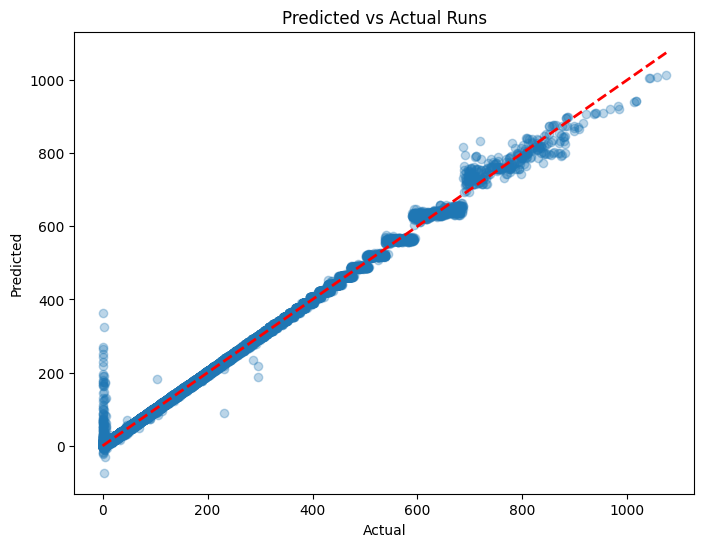

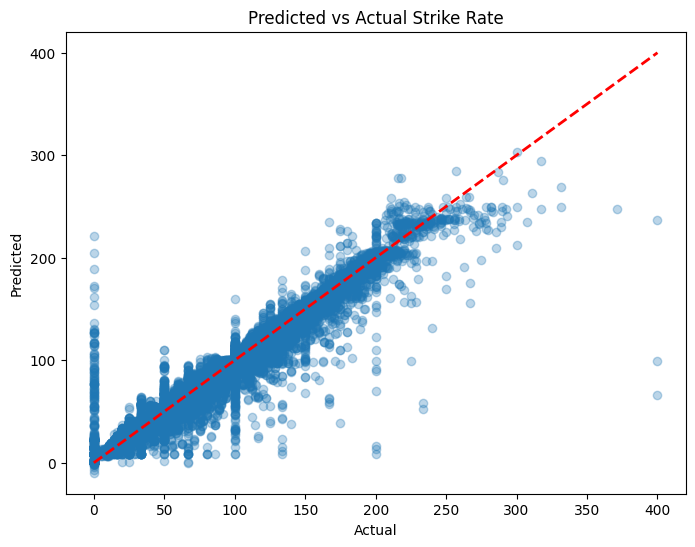

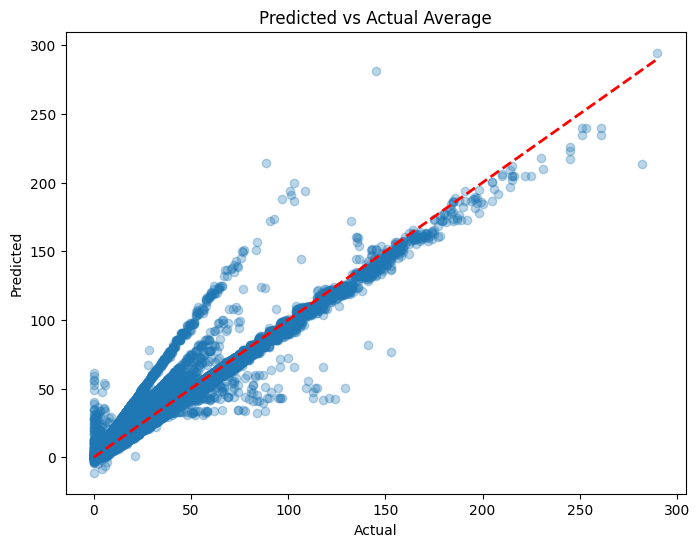

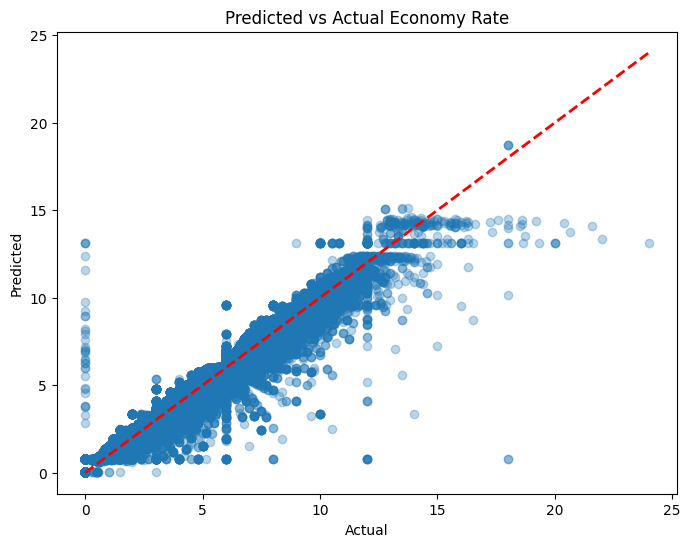

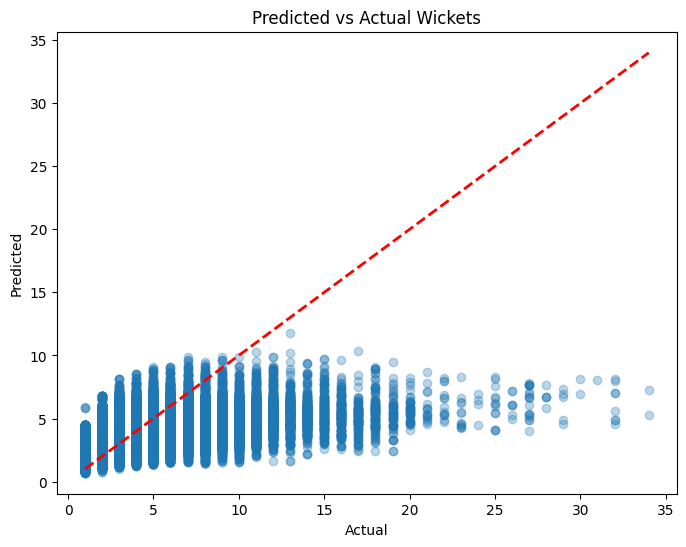

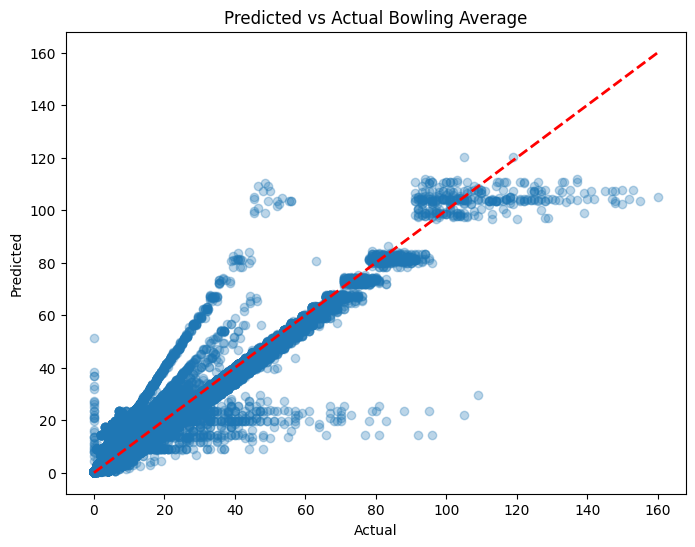

Scenario 1 Evaluation:
Runs - MAE: 2.4932, MSE: 17.4524, R²: 0.9964
Strike Rate - MAE: 7.0791, MSE: 238.6282, R²: 0.8807
Average - MAE: 4.3329, MSE: 54.9566, R²: 0.8116
Scenario 2 Evaluation:
Runs - MAE: 2.3271, MSE: 10.4608, R²: 0.9994
Strike Rate - MAE: 4.1918, MSE: 189.9448, R²: 0.8561
Average - MAE: 1.6706, MSE: 10.8752, R²: 0.9714
Scenario 1 - Predicted vs Actual Plots:


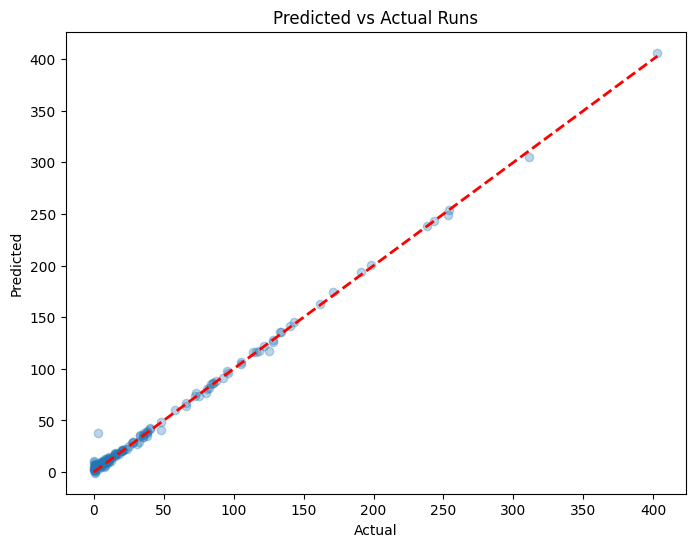

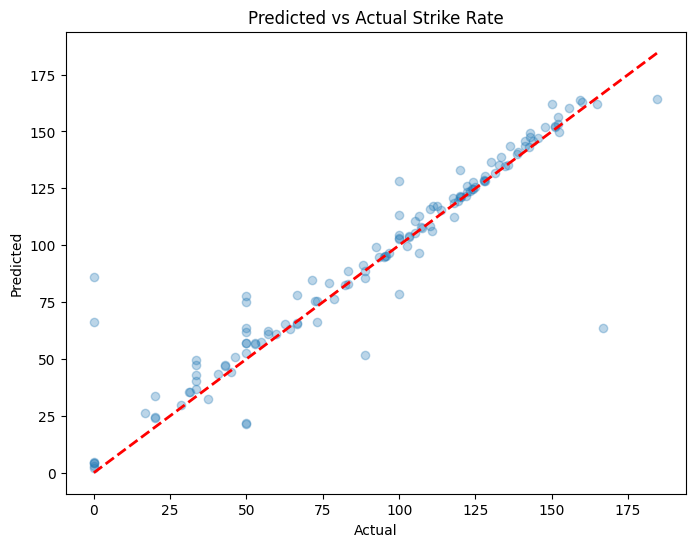

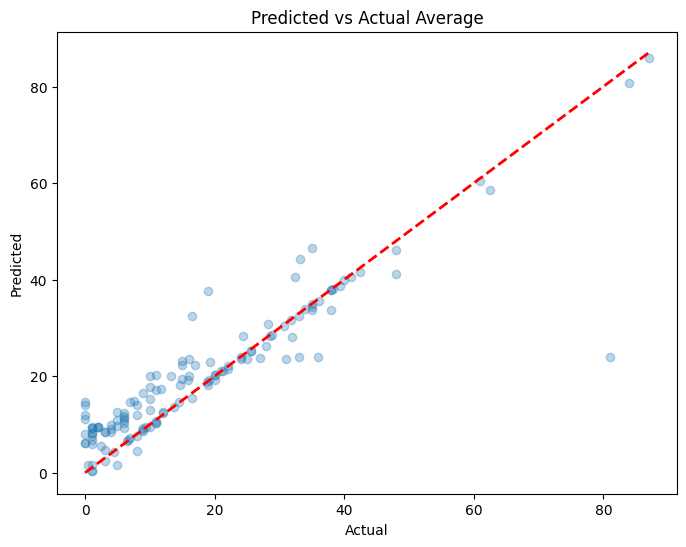

Scenario 2 - Predicted vs Actual Plots:


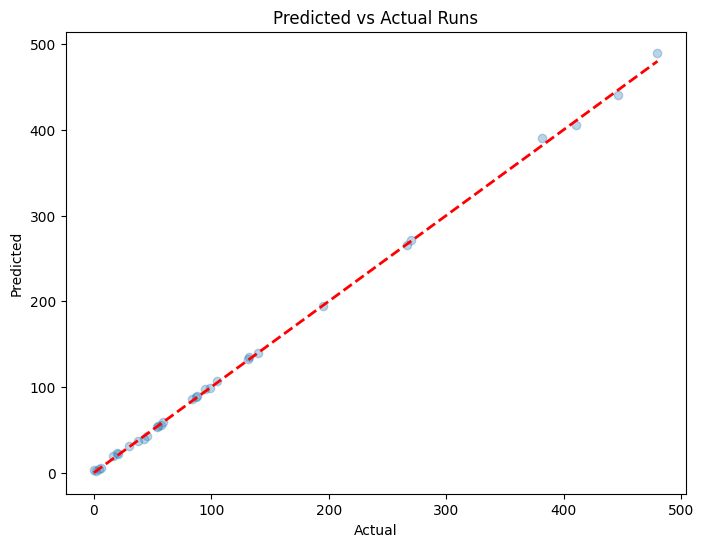

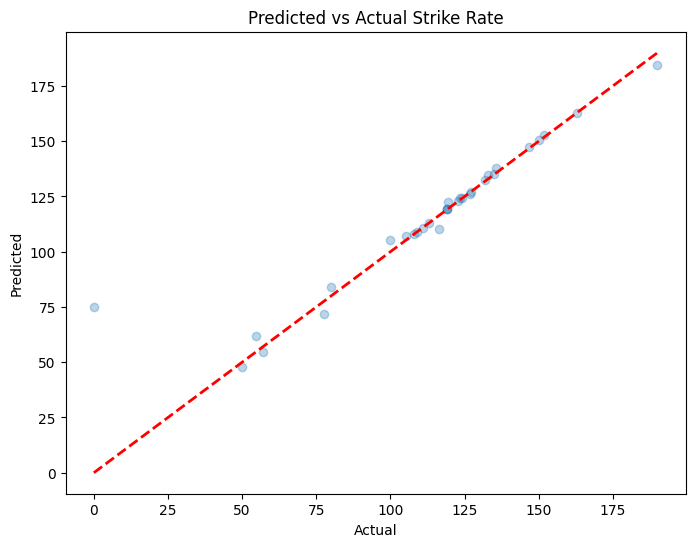

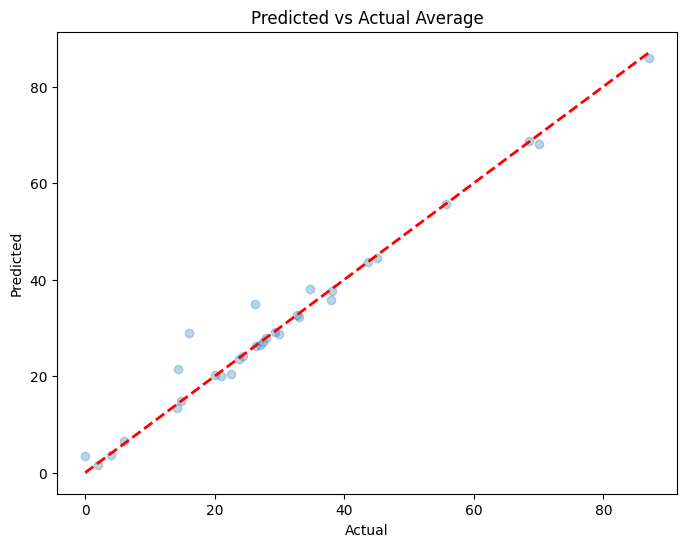

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} - MAE: {mae:.4f}, MSE: {mse:.4f}, R²: {r2:.4f}")
    return mae, mse, r2


# Evaluate batsman models
evaluate(y_test_runs, y_pred_runs, "Runs")
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
evaluate(y_test_average, y_pred_average, "Average")

# Evaluate bowler models
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
evaluate(y_test_wickets, y_pred_wickets, "Wickets")
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Plot predicted vs actual for visual inspection
def plot_predictions(y_true, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.3)
    plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', lw=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {title}')
    plt.show()

# Plot results for batsman models
plot_predictions(y_test_runs, y_pred_runs, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_predictions(y_test_average, y_pred_average, "Average")

# Plot results for bowler models
plot_predictions(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Now, let's move to the scenario testing part with imputation and testing.

# Function to create test sets for scenarios
def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
    # Scenario 1: Last match of the client team against any opponent
    scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('date').groupby('Batsman').tail(1)

    # Scenario 2: Last match of the client team against the specified opponent
    scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('date').groupby('Batsman').tail(1)

    return scenario_1, scenario_2

# Example of using the function with "India" as the client team and "Australia" as the opponent
client_team = "India"
opponent_team = "Australia"
scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

# Impute missing values in test sets
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Separate features and targets for scenario 1 and 2
X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]
X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]

X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
evaluate(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
evaluate(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
evaluate(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")

# Plot Scenario 1
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
plot_predictions(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Plot Scenario 2
print("Scenario 2 - Predicted vs Actual Plots:")
plot_predictions(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
plot_predictions(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
plot_predictions(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")



In [30]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load datasets
final_df = pd.read_csv('final_combined.csv', index_col=0)
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')

# Prepare the player information data
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Process the entire dataset
def process_dataset(df):
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    df = df.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    df = df.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    df = df.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    df['Bowling_Team'] = df.apply(lambda row: row['Batting_Team'] if row['Inning_Number'] % 2 == 0 else df['Batting_Team'].shift(-1).iloc[0], axis=1)
    df['balls_faced'] = df.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    df['total_runs'] = df.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    df['dismissals'] = (df['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    df['cumulative_dismissals'] = df.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    df['current_strike_rate'] = (df['total_runs'] / df['balls_faced']) * 100
    df['current_average'] = df['total_runs'] / df['cumulative_dismissals'].replace(0, np.nan)
    df['balls_bowled'] = df.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    df['total_runs_conceded'] = df.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    df['total_wickets'] = df.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    df['current_economy_rate'] = (df['total_runs_conceded'] / df['balls_bowled']) * 6
    df['current_bowling_average'] = df['total_runs_conceded'] / df['total_wickets'].replace(0, np.nan)

    # Feature Engineering: Creating rolling averages, lag features, and interaction terms
    df['avg_runs_last_5'] = df.groupby('Batsman')['total_runs'].rolling(5, min_periods=1).mean().reset_index(0, drop=True)
    df['lag_strike_rate'] = df.groupby('Batsman')['current_strike_rate'].shift(1)
    df['strike_rate_venue'] = df['current_strike_rate'] * df['venue'].factorize()[0]  # Categorical to numerical

    return df

processed_df = process_dataset(final_df)

# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_runs', 'next_match_strike_rate', 'next_match_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Train-Test split
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Train XGBoost models
xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}
model_runs = XGBRegressor(**xgb_params)
model_strike_rate = XGBRegressor(**xgb_params)
model_average = XGBRegressor(**xgb_params)

model_economy_rate = XGBRegressor(**xgb_params)
model_wickets = XGBRegressor(**xgb_params)
model_bowling_average = XGBRegressor(**xgb_params)

model_runs.fit(X_train_batsman_imputed, y_train_runs)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
model_average.fit(X_train_batsman_imputed, y_train_average)

model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)

# Predict on test sets
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
y_pred_average = model_average.predict(X_test_batsman_imputed)

y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)

# Evaluation function
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} - MAE: {mae:.4f}, MSE: {mse:.4f}, R²: {r2:.4f}")
    return mae, mse, r2

# Evaluate batsman models
evaluate(y_test_runs, y_pred_runs, "Runs")
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
evaluate(y_test_average, y_pred_average, "Average")

# Evaluate bowler models
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
evaluate(y_test_wickets, y_pred_wickets, "Wickets")
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Plot predicted vs actual for visual inspection
def plot_predictions(y_true, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.3)
    plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', lw=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {title}')
    plt.show()

# Plot results for batsman models
plot_predictions(y_test_runs, y_pred_runs, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_predictions(y_test_average, y_pred_average, "Average")

# Plot results for bowler models
plot_predictions(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Now, let's move to the scenario testing part with imputation and testing.

# Function to create test sets for scenarios
def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
    # Scenario 1: Last match of the client team against any opponent
    scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('date').groupby('Batsman').tail(1)

    # Scenario 2: Last match of the client team against the specified opponent
    scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('date').groupby('Batsman').tail(1)

    return scenario_1, scenario_2

# Example of using the function with "India" as the client team and "Australia" as the opponent
client_team = "India"
opponent_team = "Australia"
scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

# Impute missing values in test sets
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Separate features and targets for scenario 1 and 2
X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]
X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'strike_rate_venue']]

X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
evaluate(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
evaluate(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
evaluate(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")

# Plot Scenario 1
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
plot_predictions(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Plot Scenario 2
print("Scenario 2 - Predicted vs Actual Plots:")
plot_predictions(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
plot_predictions(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
plot_predictions(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")



KeyboardInterrupt: 

In [33]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process chunks
def process_chunk(chunk):
    chunk.reset_index(drop=True, inplace=True)  # Reset index to avoid duplicate index issues
    chunk['date'] = pd.to_datetime(chunk['date'], errors='coerce')
    chunk.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    chunk = chunk.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    chunk = chunk.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    chunk = chunk.merge(playing_role, how='left', left_on='Batsman', right_index=True)
    # Create the Bowling_Team column
    chunk['Bowling_Team'] = chunk['Batting_Team'].shift(-1)
    chunk.loc[chunk['Inning_Number'] % 2 == 1, 'Bowling_Team'] = chunk['Batting_Team']

    chunk['balls_faced'] = chunk.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    chunk['total_runs'] = chunk.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    chunk['dismissals'] = (chunk['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    chunk['cumulative_dismissals'] = chunk.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    chunk['current_strike_rate'] = (chunk['total_runs'] / chunk['balls_faced']) * 100
    chunk['current_average'] = chunk['total_runs'] / chunk['cumulative_dismissals'].replace(0, np.nan)
    chunk['balls_bowled'] = chunk.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    chunk['total_runs_conceded'] = chunk.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    chunk['total_wickets'] = chunk.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    chunk['current_economy_rate'] = (chunk['total_runs_conceded'] / chunk['balls_bowled']) * 6
    chunk['current_bowling_average'] = chunk['total_runs_conceded'] / chunk['total_wickets'].replace(0, np.nan)
    return chunk

# Load and process the entire dataset directly
df = pd.read_csv('final_combined.csv', index_col=0)
df.reset_index(drop=True, inplace=True)  # Reset index to avoid duplicate index issues
processed_df = process_chunk(df)

# Feature Engineering: Creating rolling averages and lag features without unfair information
processed_df['avg_runs_last_5'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].transform(lambda x: x.rolling(5, min_periods=1).mean())
processed_df['lag_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(1)

# Remove potentially problematic features
# Remove 'strike_rate_venue' or other similar features that might encode unfair advantage
# Remove date related features to prevent the model from memorizing the sequence
processed_df = processed_df.drop(columns=['date', 'venue'])

# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_runs', 'next_match_strike_rate', 'next_match_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Train-Test split with TimeSeriesSplit to ensure the model is validated on future data
tscv = TimeSeriesSplit(n_splits=5)

# Function to train and evaluate models using TimeSeriesSplit
def train_and_evaluate(X, y, model_params, feature_name):
    results = []
    for train_index, test_index in tscv.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Impute missing values
        imputer = SimpleImputer(strategy='mean')
        X_train_imputed = imputer.fit_transform(X_train)
        X_test_imputed = imputer.transform(X_test)

        # Train model
        model = XGBRegressor(**model_params)
        model.fit(X_train_imputed, y_train)

        # Predict and evaluate
        y_pred = model.predict(X_test_imputed)
        mae, mse, r2 = evaluate(y_test, y_pred, feature_name)
        results.append((mae, mse, r2))

    # Average results across all splits
    avg_results = pd.DataFrame(results, columns=['MAE', 'MSE', 'R²']).mean()
    print(f"Average results for {feature_name} - MAE: {avg_results['MAE']:.4f}, MSE: {avg_results['MSE']:.4f}, R²: {avg_results['R²']:.4f}")
    return avg_results

# XGBoost parameters
xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}

# Train and evaluate batsman models
train_and_evaluate(X_batsman, y_runs, xgb_params, "Runs")
train_and_evaluate(X_batsman, y_strike_rate, xgb_params, "Strike Rate")
train_and_evaluate(X_batsman, y_average, xgb_params, "Average")

# Train and evaluate bowler models
train_and_evaluate(X_bowler, y_economy_rate, xgb_params, "Economy Rate")
train_and_evaluate(X_bowler, y_wickets, xgb_params, "Wickets")
train_and_evaluate(X_bowler, y_bowling_average, xgb_params, "Bowling Average")

# Now, let's move to the scenario testing part with imputation and testing.

# Function to create test sets for scenarios
def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
    # Scenario 1: Last match of the client team against any opponent
    scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('Inning_Number').groupby('Batsman').tail(1)

    # Scenario 2: Last match of the client team against the specified opponent
    scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('Inning_Number').groupby('Batsman').tail(1)

    return scenario_1, scenario_2

# Example of using the function with "India" as the client team and "Australia" as the opponent
client_team = "India"
opponent_team = "Australia"
scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

# Impute missing values in test sets
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Separate features and targets for scenario 1 and 2
X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]

X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
evaluate(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
evaluate(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
evaluate(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")

# Plot Scenario 1
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
plot_predictions(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Plot Scenario 2
print("Scenario 2 - Predicted vs Actual Plots:")
plot_predictions(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
plot_predictions(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
plot_predictions(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")



Runs - MAE: 18.4676, MSE: 9934.1765, R²: 0.9481
Runs - MAE: 10.1597, MSE: 2660.5213, R²: 0.9901
Runs - MAE: 9.0060, MSE: 2005.1558, R²: 0.9936
Runs - MAE: 12.9545, MSE: 4703.9805, R²: 0.9881
Runs - MAE: 19.6416, MSE: 8693.5290, R²: 0.9867
Average results for Runs - MAE: 14.0459, MSE: 5599.4726, R²: 0.9813
Strike Rate - MAE: 1.3116, MSE: 14.4395, R²: 0.9859
Strike Rate - MAE: 1.1485, MSE: 12.9209, R²: 0.9871
Strike Rate - MAE: 0.9734, MSE: 8.5026, R²: 0.9918
Strike Rate - MAE: 1.1082, MSE: 14.9031, R²: 0.9851
Strike Rate - MAE: 0.7795, MSE: 7.6061, R²: 0.9897
Average results for Strike Rate - MAE: 1.0643, MSE: 11.6744, R²: 0.9879
Average - MAE: 0.6895, MSE: 15.6228, R²: 0.9328
Average - MAE: 0.5442, MSE: 10.8154, R²: 0.9418
Average - MAE: 0.3681, MSE: 1.6179, R²: 0.9874
Average - MAE: 0.4656, MSE: 3.1915, R²: 0.9786
Average - MAE: 0.3300, MSE: 2.0008, R²: 0.9810
Average results for Average - MAE: 0.4795, MSE: 6.6497, R²: 0.9643
Economy Rate - MAE: 0.2209, MSE: 0.2105, R²: 0.9582
Economy

ValueError: Feature shape mismatch, expected: 5, got 4

Runs - MAE: 4.0010, MSE: 123.3088, R²: 0.9996
Strike Rate - MAE: 1.1603, MSE: 12.4134, R²: 0.9876
Average - MAE: 0.5381, MSE: 5.4933, R²: 0.9704
Economy Rate - MAE: 0.2144, MSE: 0.2071, R²: 0.9597
Wickets - MAE: 1.9425, MSE: 9.0533, R²: 0.3182
Bowling Average - MAE: 1.1714, MSE: 12.1225, R²: 0.9551


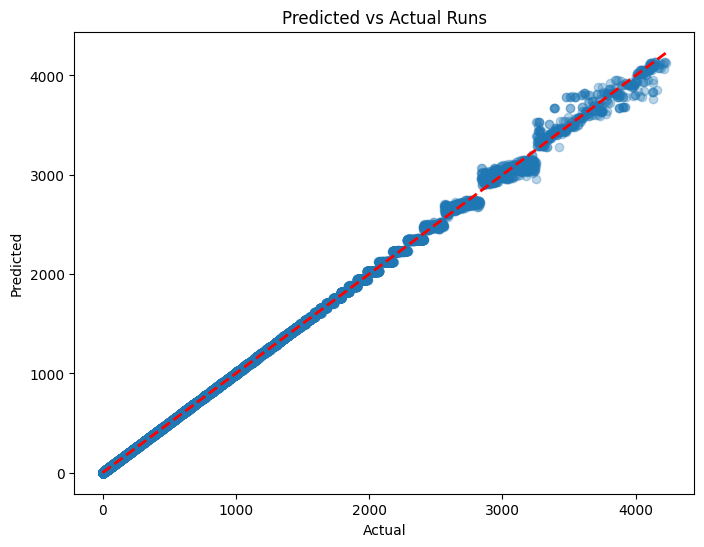

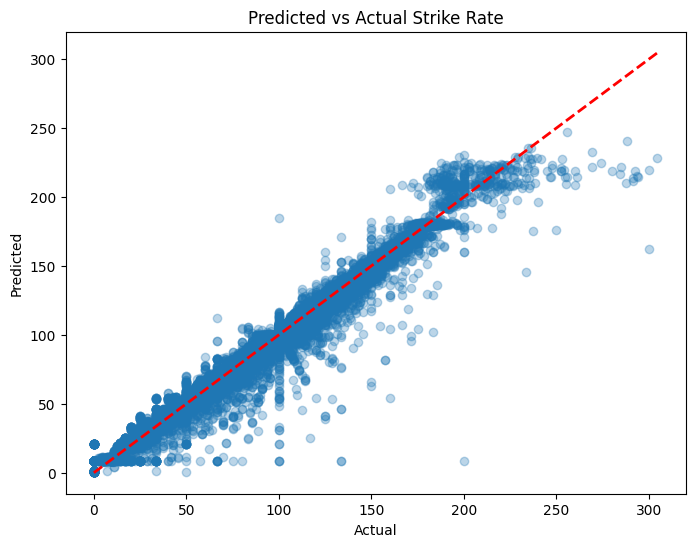

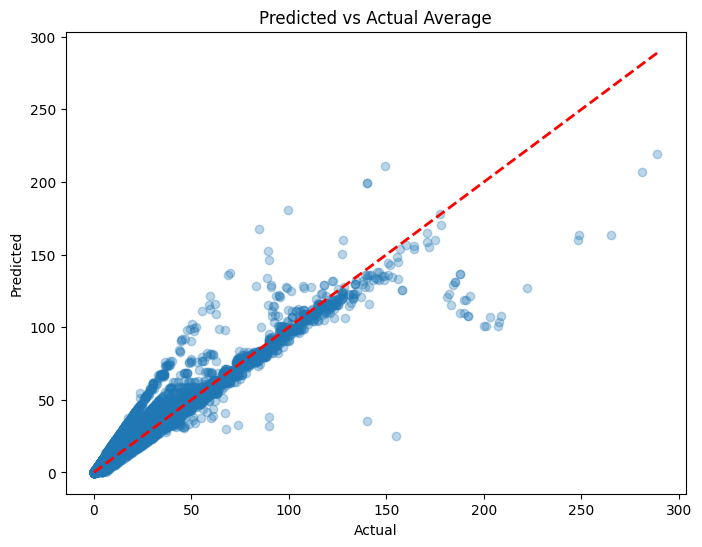

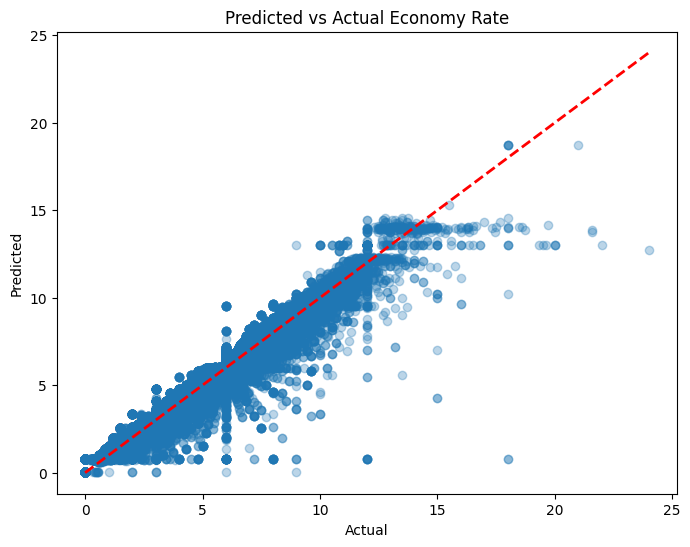

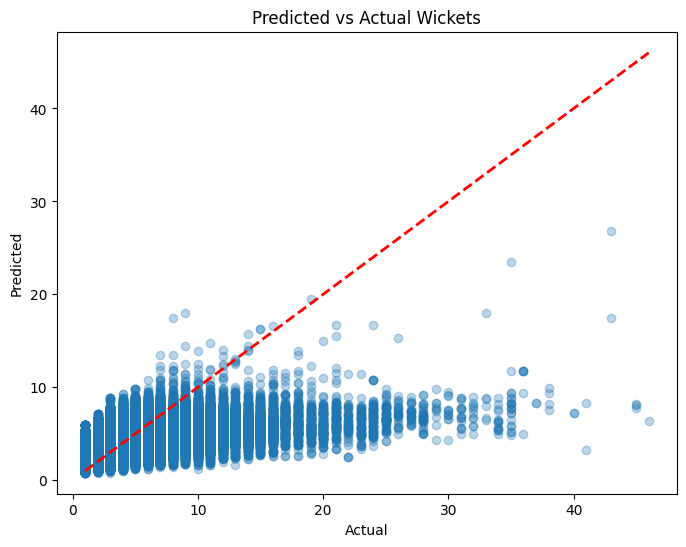

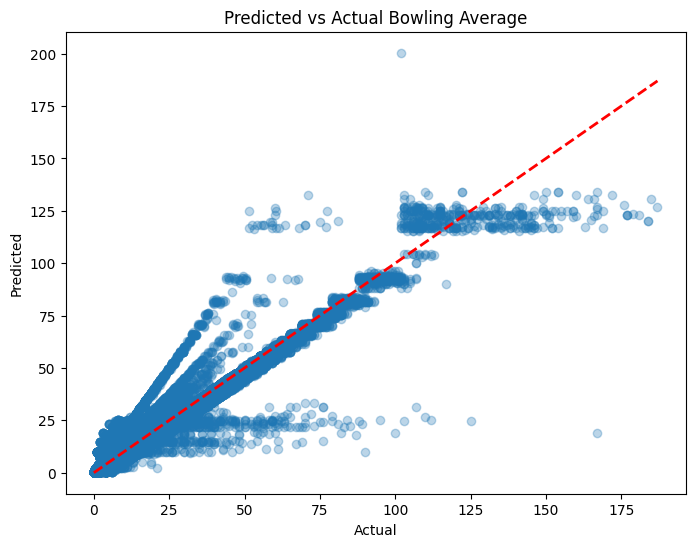

Scenario 1 Evaluation:
Runs - MAE: 2.1906, MSE: 16.8364, R²: 0.9999
Strike Rate - MAE: 5.6627, MSE: 133.5584, R²: 0.9216
Average - MAE: 1.6018, MSE: 8.4886, R²: 0.9599
Scenario 2 Evaluation:
Runs - MAE: 1.9633, MSE: 4.3253, R²: 0.9999
Strike Rate - MAE: 2.5081, MSE: 10.5522, R²: 0.9098
Average - MAE: 2.3327, MSE: 14.8682, R²: 0.7893
Scenario 1 - Predicted vs Actual Plots:


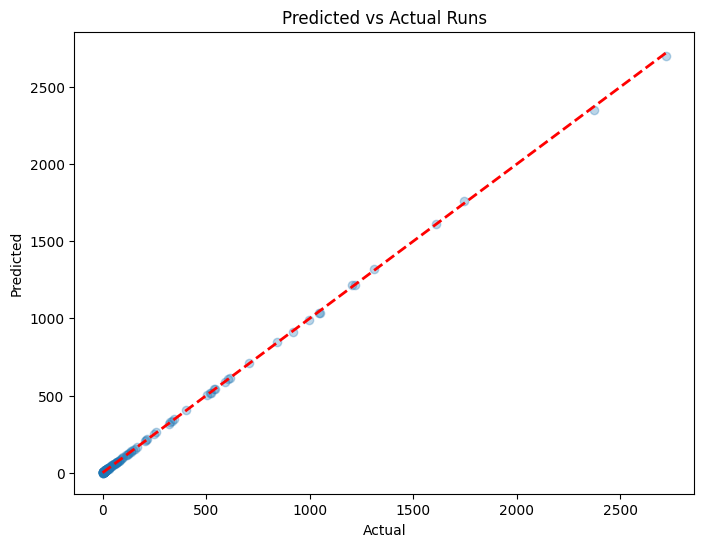

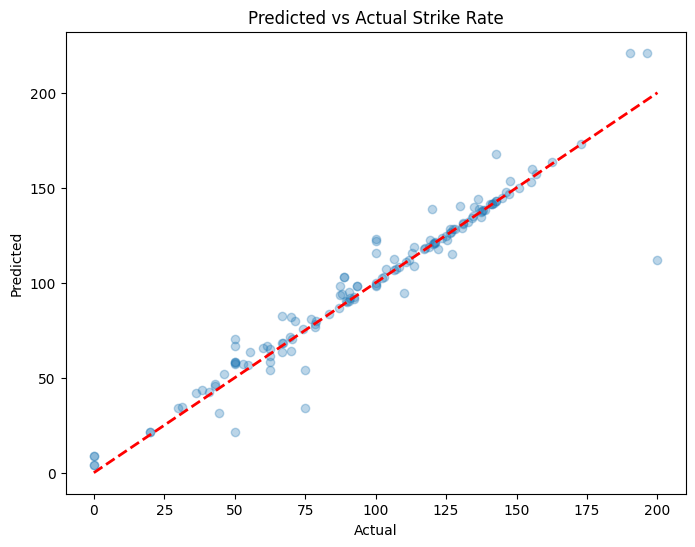

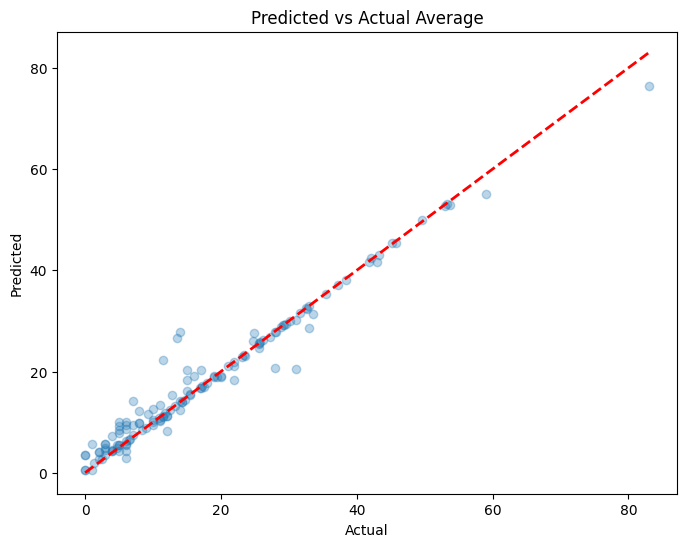

Scenario 2 - Predicted vs Actual Plots:


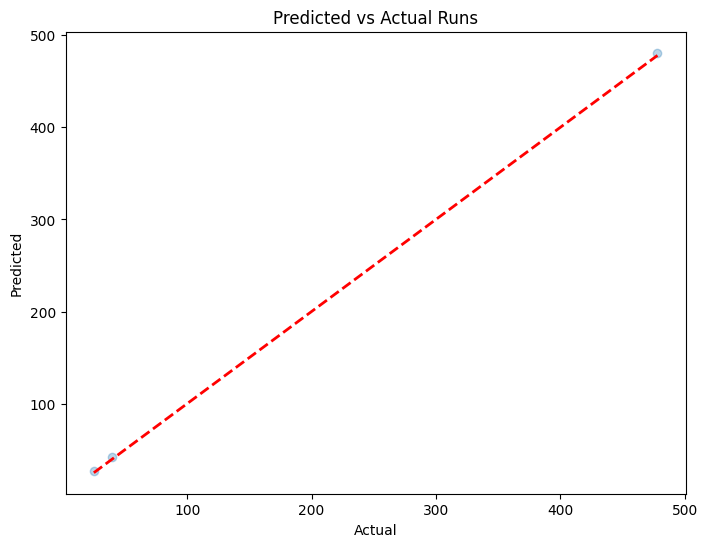

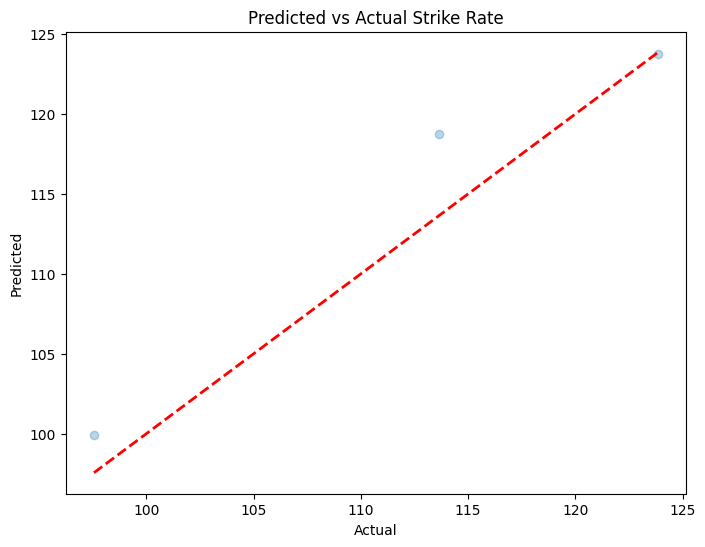

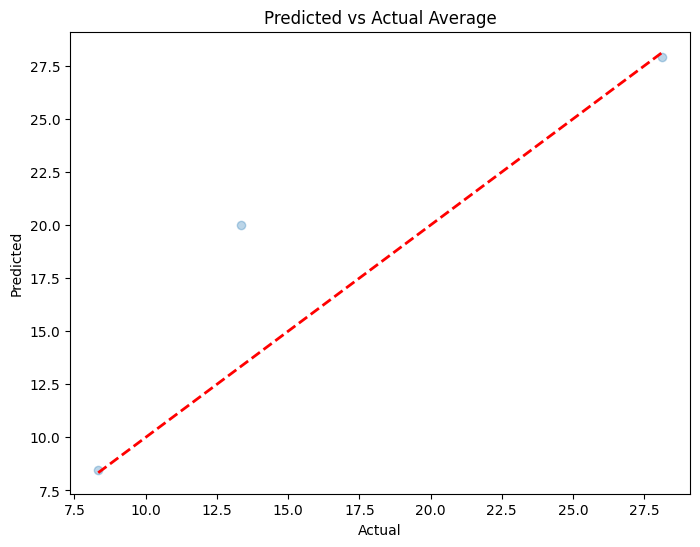

In [34]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process data
def process_data(df):
    df.reset_index(drop=True, inplace=True)
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    df = df.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    df = df.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    df = df.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Create Bowling_Team column
    df['Bowling_Team'] = df['Batting_Team'].shift(-1)
    df.loc[df['Inning_Number'] % 2 == 1, 'Bowling_Team'] = df['Batting_Team']

    df['balls_faced'] = df.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    df['total_runs'] = df.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    df['dismissals'] = (df['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    df['cumulative_dismissals'] = df.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    df['current_strike_rate'] = (df['total_runs'] / df['balls_faced']) * 100
    df['current_average'] = df['total_runs'] / df['cumulative_dismissals'].replace(0, np.nan)
    df['balls_bowled'] = df.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    df['total_runs_conceded'] = df.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    df['total_wickets'] = df.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    df['current_economy_rate'] = (df['total_runs_conceded'] / df['balls_bowled']) * 6
    df['current_bowling_average'] = df['total_runs_conceded'] / df['total_wickets'].replace(0, np.nan)
    return df

# Load and process the entire dataset directly
df = pd.read_csv('final_combined.csv', index_col=0)
processed_df = process_data(df)

# Feature Engineering: Creating rolling averages and lag features without unfair information
processed_df['avg_runs_last_5'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].transform(lambda x: x.rolling(5, min_periods=1).mean())
processed_df['lag_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(1)

# Remove potentially problematic features
processed_df = processed_df.drop(columns=['date', 'venue'])

# Create target variables for the next match performance against the same team
processed_df['next_match_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_runs', 'next_match_strike_rate', 'next_match_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
y_runs = processed_df['next_match_runs']
y_strike_rate = processed_df['next_match_strike_rate']
y_average = processed_df['next_match_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# General train-test split
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Function to evaluate models
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} - MAE: {mae:.4f}, MSE: {mse:.4f}, R²: {r2:.4f}")
    return mae, mse, r2

# XGBoost parameters
xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}

# Train and evaluate on general train-test split
model_runs = XGBRegressor(**xgb_params)
model_runs.fit(X_train_batsman_imputed, y_train_runs)
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
evaluate(y_test_runs, y_pred_runs, "Runs")

model_strike_rate = XGBRegressor(**xgb_params)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")

model_average = XGBRegressor(**xgb_params)
model_average.fit(X_train_batsman_imputed, y_train_average)
y_pred_average = model_average.predict(X_test_batsman_imputed)
evaluate(y_test_average, y_pred_average, "Average")

model_economy_rate = XGBRegressor(**xgb_params)
model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")

model_wickets = XGBRegressor(**xgb_params)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
evaluate(y_test_wickets, y_pred_wickets, "Wickets")

model_bowling_average = XGBRegressor(**xgb_params)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Plot predicted vs actual for visual inspection
def plot_predictions(y_true, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.3)
    plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', lw=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {title}')
    plt.show()

# Plot results for batsman models
plot_predictions(y_test_runs, y_pred_runs, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_predictions(y_test_average, y_pred_average, "Average")

# Plot results for bowler models
plot_predictions(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Now, let's move to the scenario testing part with imputation and testing.

# Function to create test sets for scenarios
def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
    # Scenario 1: Last match of the client team against any opponent
    scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('Inning_Number').groupby('Batsman').tail(1)

    # Scenario 2: Last match of the client team against the specified opponent
    scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('Inning_Number').groupby('Batsman').tail(1)

    return scenario_1, scenario_2

# Example of using the function with "India" as the client team and "Australia" as the opponent
client_team = "India"
opponent_team = "Australia"
scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

# Impute missing values in test sets
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Separate features and targets for scenario 1 and 2
X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]

X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
evaluate(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
evaluate(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
evaluate(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
evaluate(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")

# Plot Scenario 1
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(scenario_1_df['next_match_runs'], y_pred_runs_scenario_1, "Runs")
plot_predictions(scenario_1_df['next_match_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(scenario_1_df['next_match_average'], y_pred_average_scenario_1, "Average")

# Plot Scenario 2
print("Scenario 2 - Predicted vs Actual Plots:")
plot_predictions(scenario_2_df['next_match_runs'], y_pred_runs_scenario_2, "Runs")
plot_predictions(scenario_2_df['next_match_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
plot_predictions(scenario_2_df['next_match_average'], y_pred_average_scenario_2, "Average")



Overfitting detected due to cumuative scores.


Evaluating Batsman Models:
Runs - MAE: 4.0010, MSE: 123.3088, R²: 0.9996


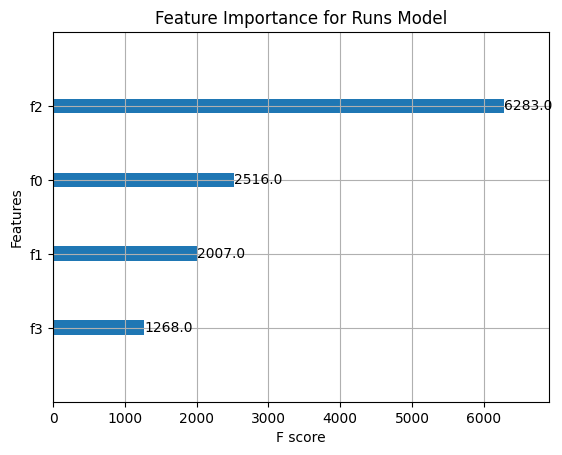

Strike Rate - MAE: 1.1603, MSE: 12.4134, R²: 0.9876


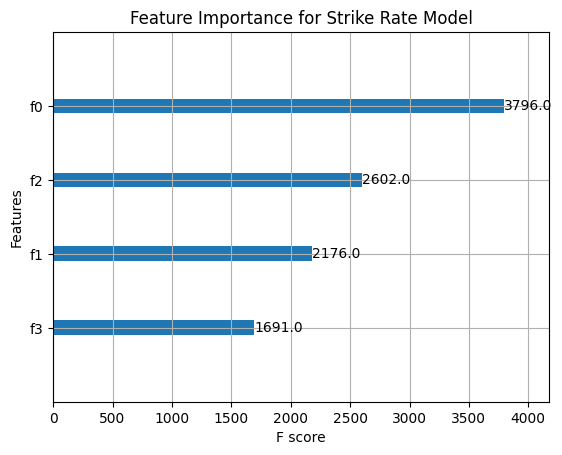

Average - MAE: 0.5381, MSE: 5.4933, R²: 0.9704


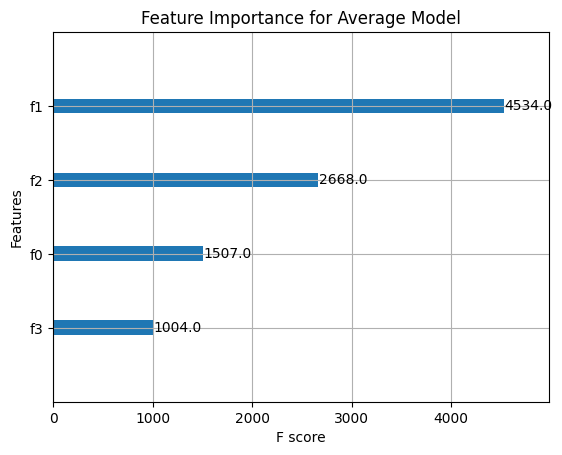

In [42]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor, plot_importance
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process data
def process_data(df):
    df.reset_index(drop=True, inplace=True)
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    df = df.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    df = df.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    df = df.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Create Bowling_Team column
    df['Bowling_Team'] = df['Batting_Team'].shift(-1)
    df.loc[df['Inning_Number'] % 2 == 1, 'Bowling_Team'] = df['Batting_Team']

    df['balls_faced'] = df.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    df['total_runs'] = df.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    df['dismissals'] = (df['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    df['cumulative_dismissals'] = df.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    df['current_strike_rate'] = (df['total_runs'] / df['balls_faced']) * 100
    df['current_average'] = df['total_runs'] / df['cumulative_dismissals'].replace(0, np.nan)
    df['balls_bowled'] = df.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    df['total_runs_conceded'] = df.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    df['total_wickets'] = df.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    df['current_economy_rate'] = (df['total_runs_conceded'] / df['balls_bowled']) * 6
    df['current_bowling_average'] = df['total_runs_conceded'] / df['total_wickets'].replace(0, np.nan)
    return df

# Load and process the entire dataset directly
df = pd.read_csv('final_combined.csv', index_col=0)
processed_df = process_data(df)

# Feature Engineering: Creating rolling averages and lag features without unfair information
processed_df['avg_runs_last_5'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].transform(lambda x: x.rolling(5, min_periods=1).mean())
processed_df['lag_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(1)

# Remove potentially problematic features
processed_df = processed_df.drop(columns=['venue'])

# Create target variables for the next match performance against the same team
processed_df['next_match_total_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_current_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_current_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_total_runs', 'next_match_current_strike_rate', 'next_match_current_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
y_runs = processed_df['next_match_total_runs']
y_strike_rate = processed_df['next_match_current_strike_rate']
y_average = processed_df['next_match_current_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# General train-test split
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Function to evaluate models
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} - MAE: {mae:.4f}, MSE: {mse:.4f}, R²: {r2:.4f}")
    return mae, mse, r2

# XGBoost parameters
xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}

# Train and evaluate on general train-test split
print("\nEvaluating Batsman Models:")
model_runs = XGBRegressor(**xgb_params)
model_runs.fit(X_train_batsman_imputed, y_train_runs)
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
evaluate(y_test_runs, y_pred_runs, "Runs")
plot_importance(model_runs)
plt.title("Feature Importance for Runs Model")
plt.show()

model_strike_rate = XGBRegressor(**xgb_params)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_importance(model_strike_rate)
plt.title("Feature Importance for Strike Rate Model")
plt.show()

model_average = XGBRegressor(**xgb_params)
model_average.fit(X_train_batsman_imputed, y_train_average)
y_pred_average = model_average.predict(X_test_batsman_imputed)
evaluate(y_test_average, y_pred_average, "Average")
plot_importance(model_average)
plt.title("Feature Importance for Average Model")
plt.show()





Evaluating Bowler Models:
Economy Rate - MAE: 0.2144, MSE: 0.2071, R²: 0.9597


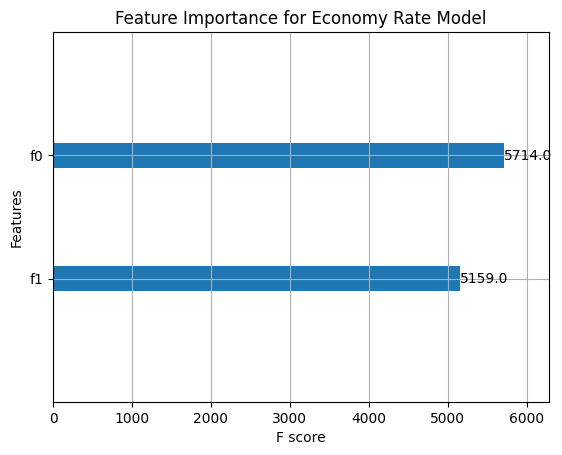

Wickets - MAE: 1.9425, MSE: 9.0533, R²: 0.3182


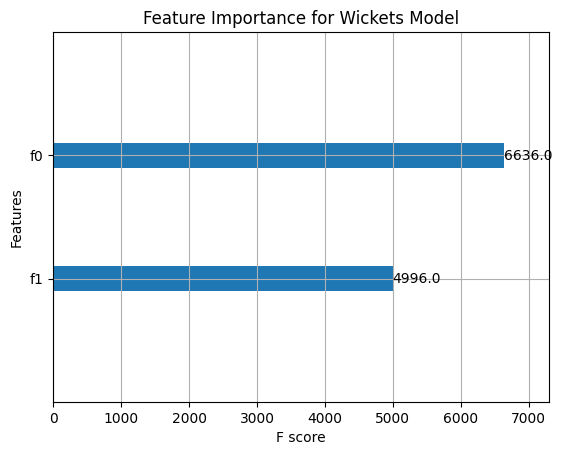

Bowling Average - MAE: 1.1714, MSE: 12.1225, R²: 0.9551


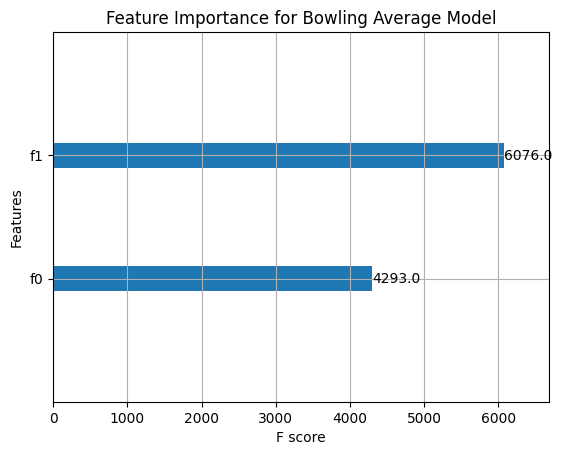


Plotting Batsman Models:


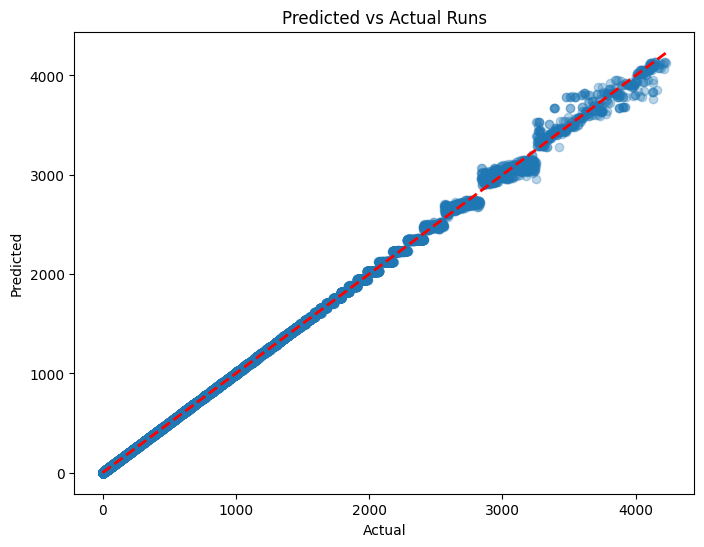

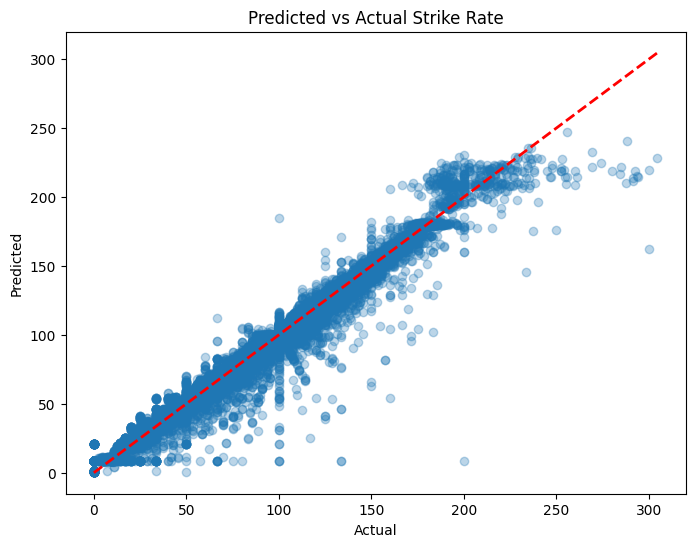

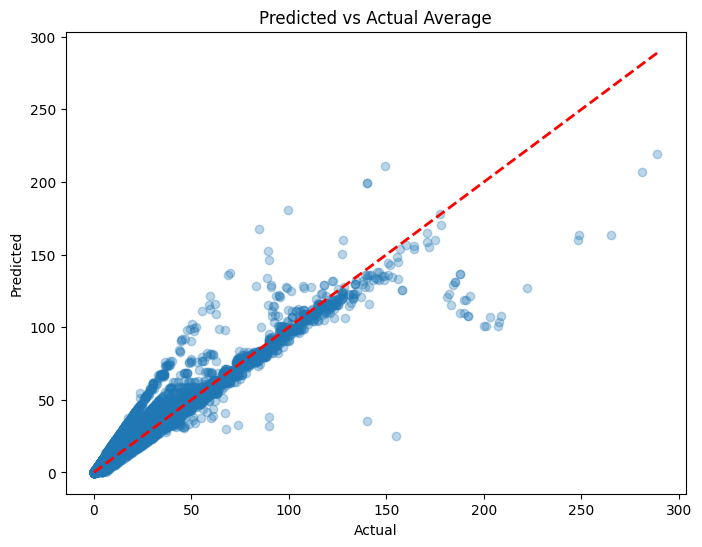


Plotting Bowler Models:


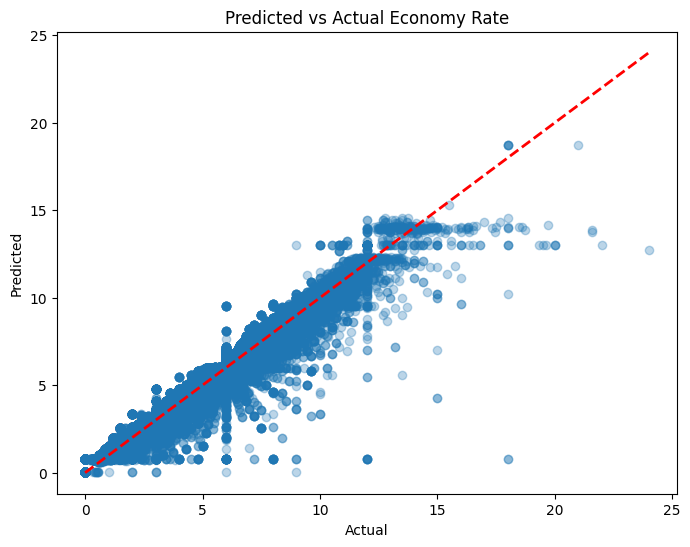

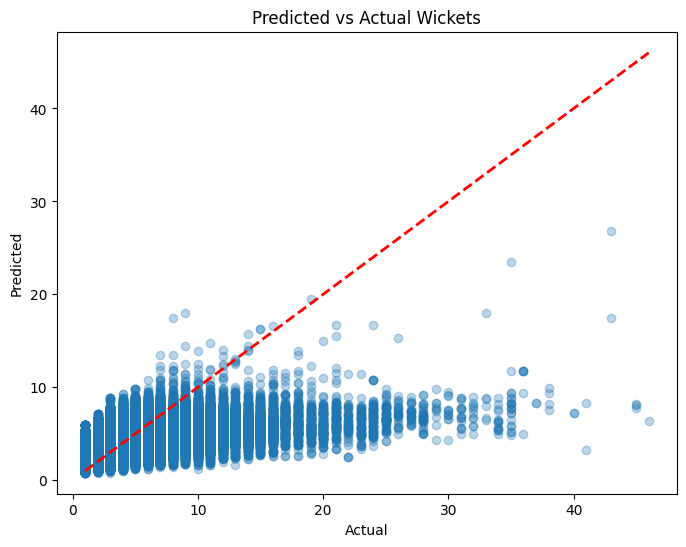

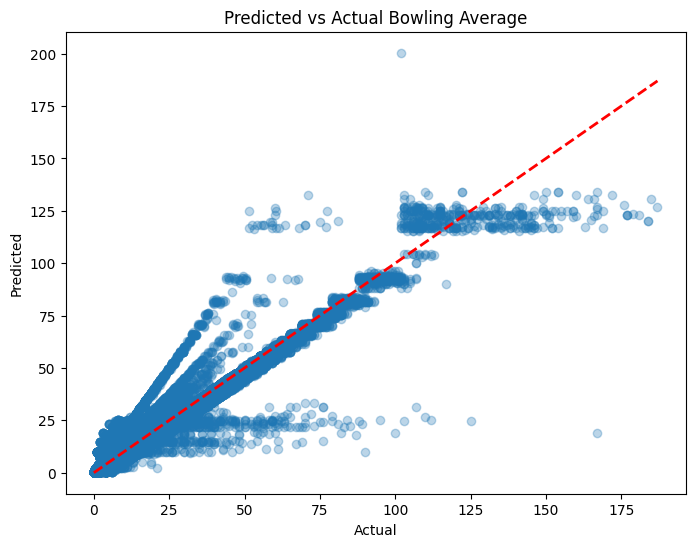

Scenario 1 Evaluation:
Runs - MAE: 2.8448, MSE: 42.2863, R²: 0.9999
Strike Rate - MAE: 4.0259, MSE: 52.8866, R²: 0.9618
Average - MAE: 1.4019, MSE: 11.8628, R²: 0.9294
Scenario 2 Evaluation:
Runs - MAE: 1.9633, MSE: 4.3253, R²: 0.9999
Strike Rate - MAE: 2.5081, MSE: 10.5522, R²: 0.9098
Average - MAE: 2.3327, MSE: 14.8682, R²: 0.7893
Scenario 1 - Predicted vs Actual Plots:


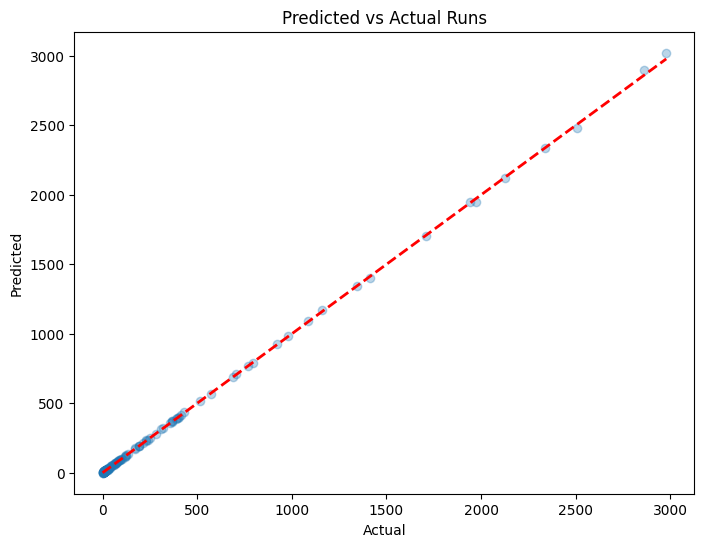

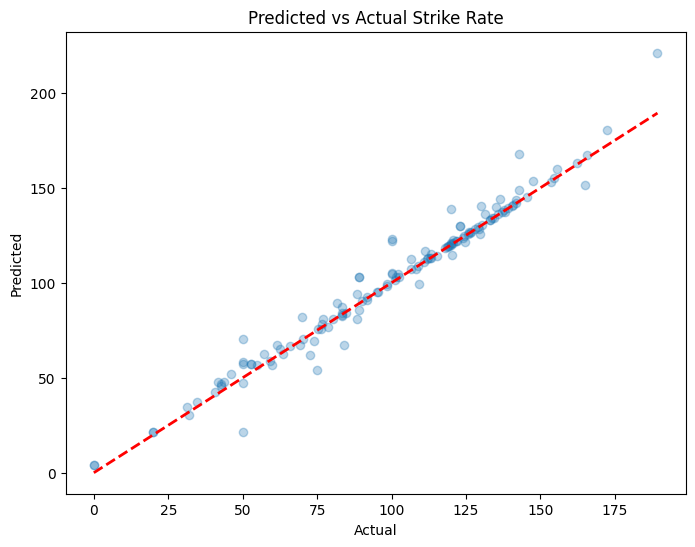

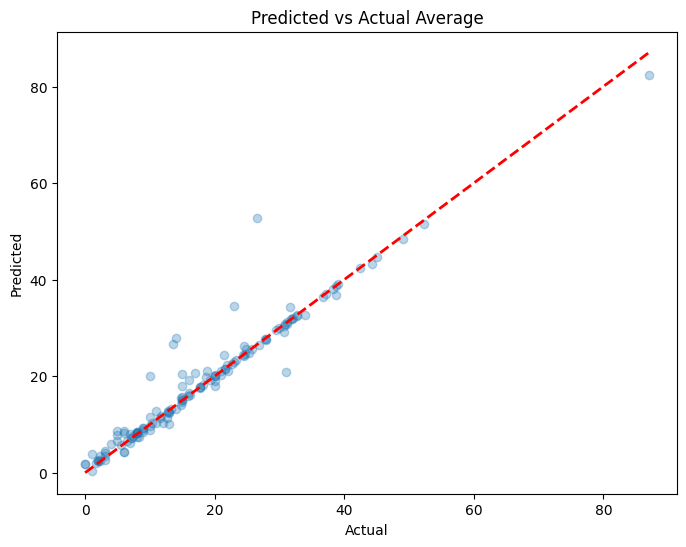

Scenario 2 - Predicted vs Actual Plots:


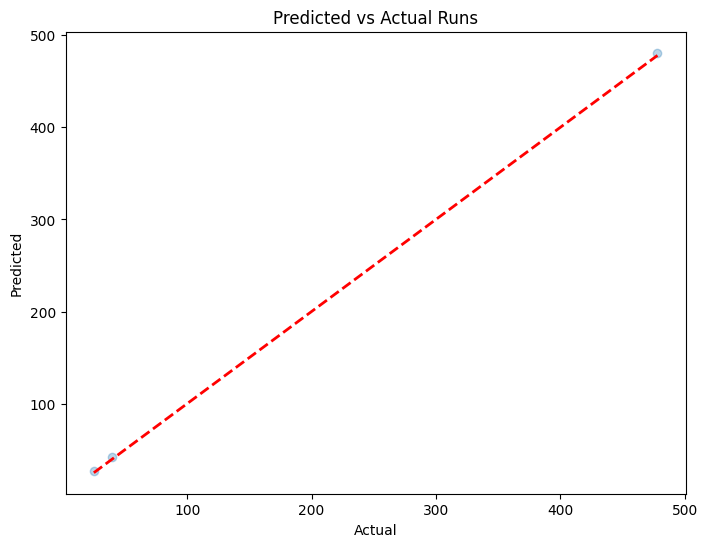

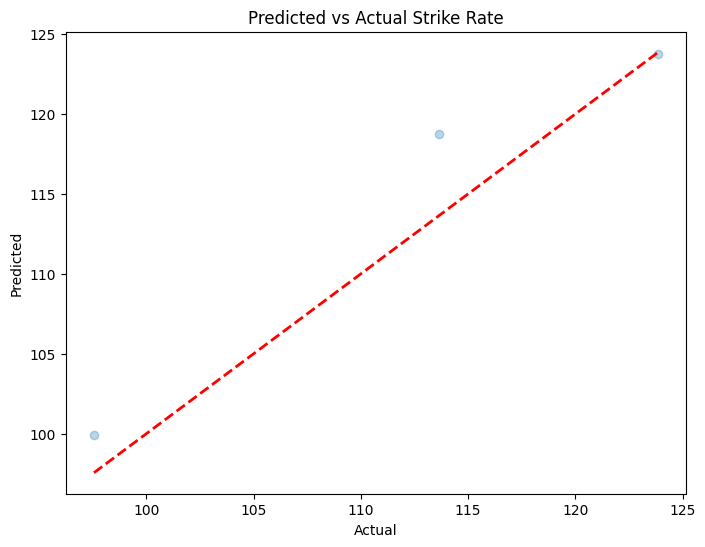

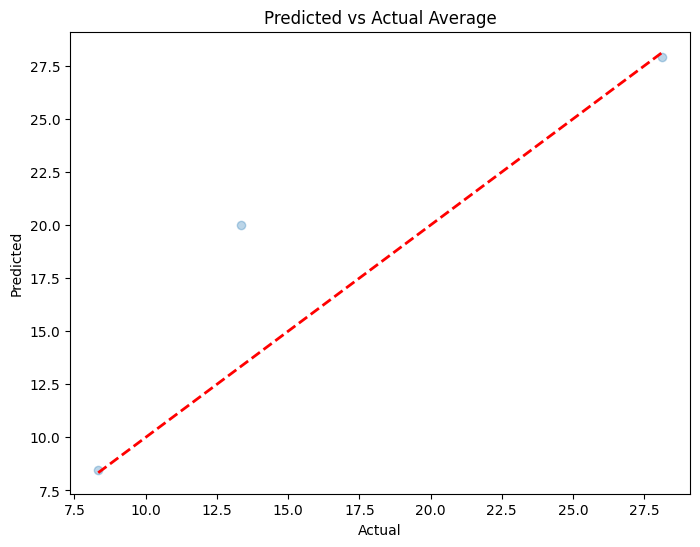

In [43]:

print("\nEvaluating Bowler Models:")
model_economy_rate = XGBRegressor(**xgb_params)
model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_importance(model_economy_rate)
plt.title("Feature Importance for Economy Rate Model")
plt.show()

model_wickets = XGBRegressor(**xgb_params)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
evaluate(y_test_wickets, y_pred_wickets, "Wickets")
plot_importance(model_wickets)
plt.title("Feature Importance for Wickets Model")
plt.show()

model_bowling_average = XGBRegressor(**xgb_params)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")
plot_importance(model_bowling_average)
plt.title("Feature Importance for Bowling Average Model")
plt.show()

# Plot predicted vs actual for visual inspection
def plot_predictions(y_true, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.3)
    plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', lw=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Predicted vs Actual {title}')
    plt.show()

# Plot results for batsman models
print("\nPlotting Batsman Models:")
plot_predictions(y_test_runs, y_pred_runs, "Runs")
plot_predictions(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_predictions(y_test_average, y_pred_average, "Average")

# Plot results for bowler models
print("\nPlotting Bowler Models:")
plot_predictions(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_predictions(y_test_wickets, y_pred_wickets, "Wickets")
plot_predictions(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

# Now, let's move to the scenario testing part with imputation and testing.

# Function to create test sets for scenarios
def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
    # Scenario 1: Last match of the client team against any opponent
    scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('date', ascending=False).groupby('Batsman').first().reset_index()

    # Scenario 2: Last match of the client team against the specified opponent
    if opponent_team:
        scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('date', ascending=False).groupby('Batsman').first().reset_index()
    else:
        scenario_2 = pd.DataFrame()

    return scenario_1, scenario_2

# Example of using the function with "India" as the client team and "Australia" as the opponent
client_team = "India"
opponent_team = "Australia"
scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

# Impute missing values in test sets
def impute_missing_values(X_test):
    imputer = SimpleImputer(strategy='mean')
    return imputer.fit_transform(X_test)

# Separate features and targets for scenario 1 and 2
X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]

X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

# Scenario 1 Predictions
y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

# Scenario 2 Predictions
y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

# Evaluate Scenario 1
print("Scenario 1 Evaluation:")
evaluate(scenario_1_df['next_match_total_runs'], y_pred_runs_scenario_1, "Runs")
evaluate(scenario_1_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
evaluate(scenario_1_df['next_match_current_average'], y_pred_average_scenario_1, "Average")

# Evaluate Scenario 2
print("Scenario 2 Evaluation:")
if not scenario_2_df.empty:
    evaluate(scenario_2_df['next_match_total_runs'], y_pred_runs_scenario_2, "Runs")
    evaluate(scenario_2_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
    evaluate(scenario_2_df['next_match_current_average'], y_pred_average_scenario_2, "Average")

# Plot Scenario 1
print("Scenario 1 - Predicted vs Actual Plots:")
plot_predictions(scenario_1_df['next_match_total_runs'], y_pred_runs_scenario_1, "Runs")
plot_predictions(scenario_1_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
plot_predictions(scenario_1_df['next_match_current_average'], y_pred_average_scenario_1, "Average")

# Plot Scenario 2
if not scenario_2_df.empty:
    print("Scenario 2 - Predicted vs Actual Plots:")
    plot_predictions(scenario_2_df['next_match_total_runs'], y_pred_runs_scenario_2, "Runs")
    plot_predictions(scenario_2_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
    plot_predictions(scenario_2_df['next_match_current_average'], y_pred_average_scenario_2, "Average")



Evaluating Batsman Models:
Runs - MAE: 4.0010, MSE: 123.3088, R²: 0.9996


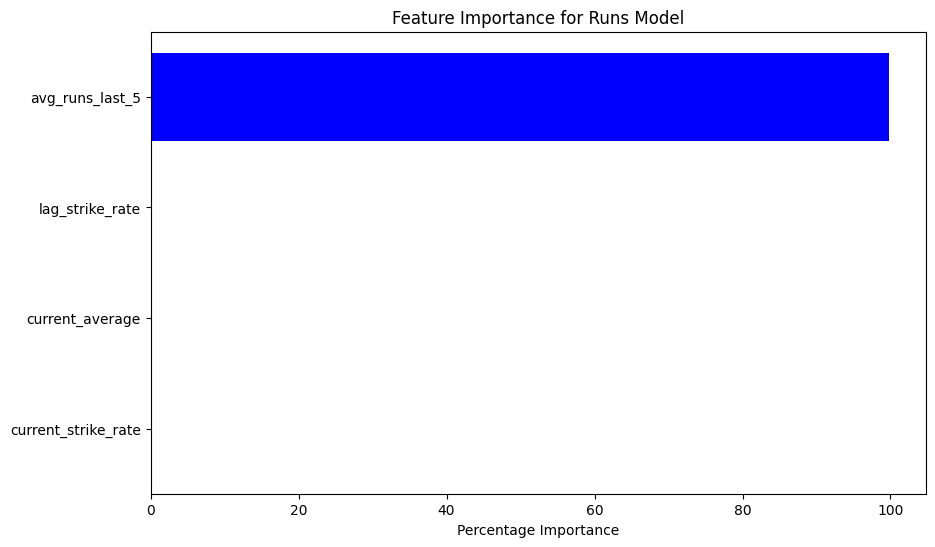

Strike Rate - MAE: 1.1603, MSE: 12.4134, R²: 0.9876


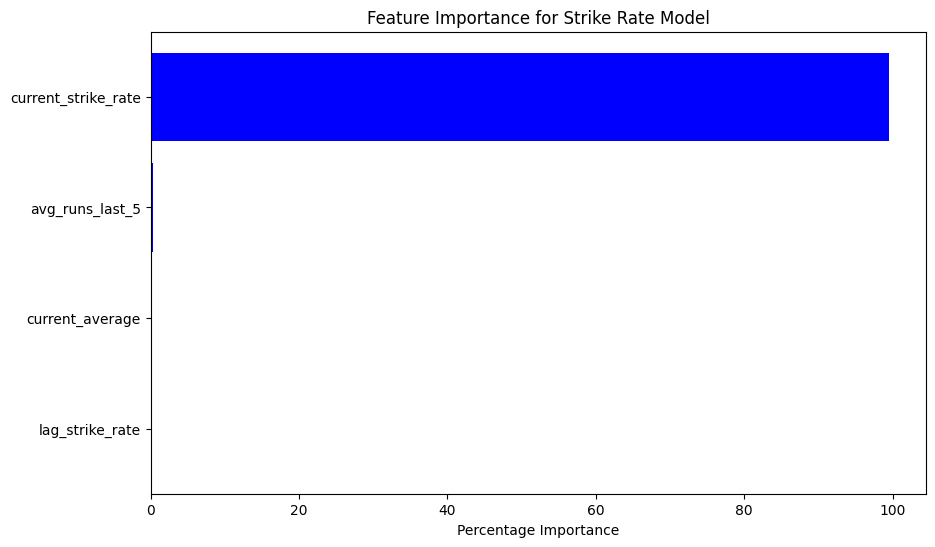

Average - MAE: 0.5381, MSE: 5.4933, R²: 0.9704


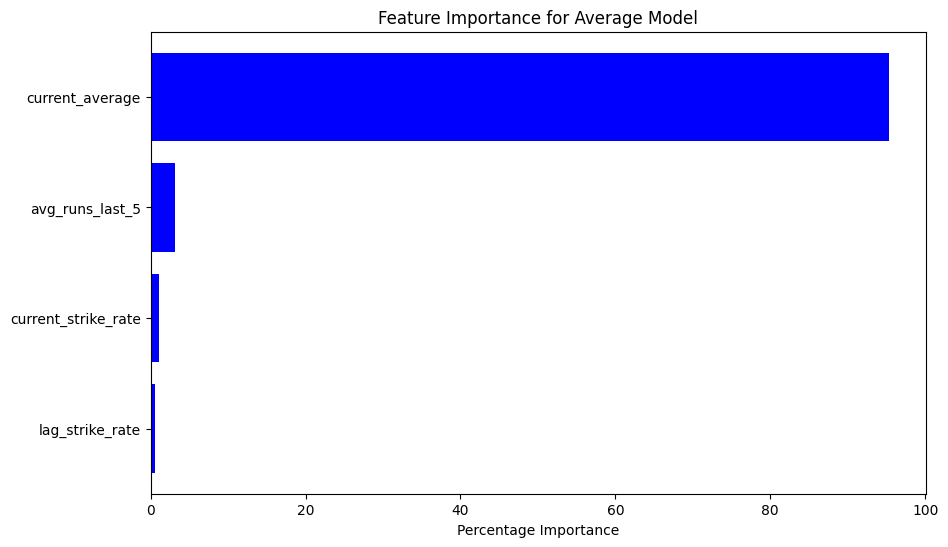


Evaluating Bowler Models:
Economy Rate - MAE: 0.2144, MSE: 0.2071, R²: 0.9597


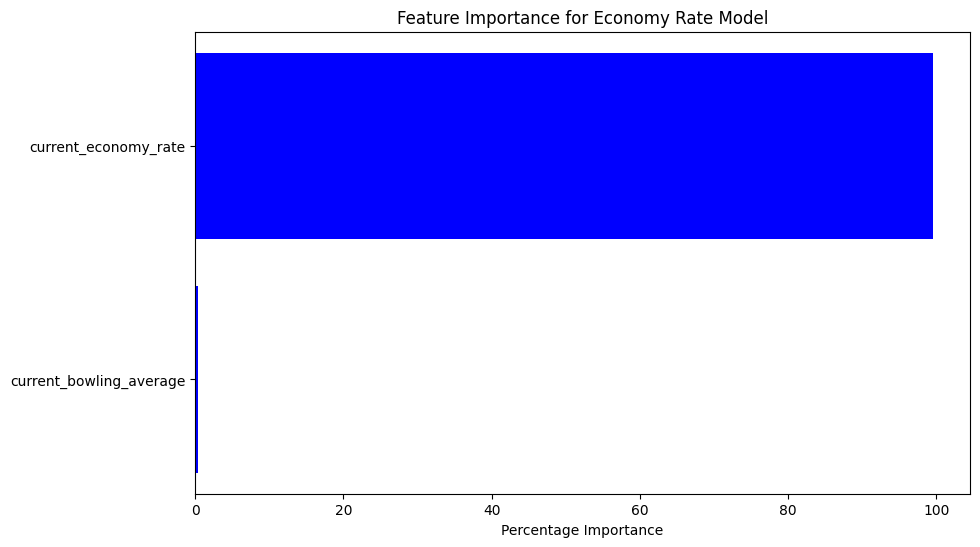

Wickets - MAE: 1.9425, MSE: 9.0533, R²: 0.3182


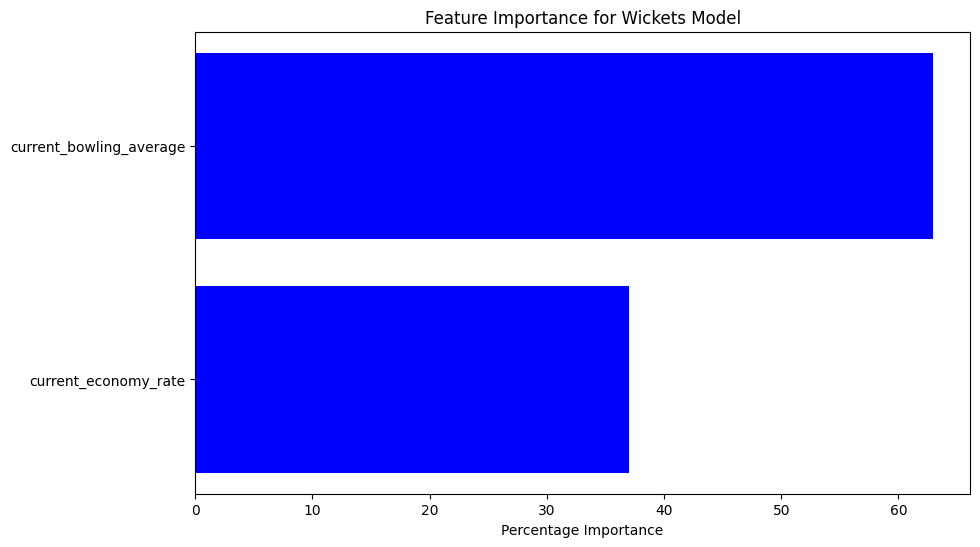

Bowling Average - MAE: 1.1714, MSE: 12.1225, R²: 0.9551


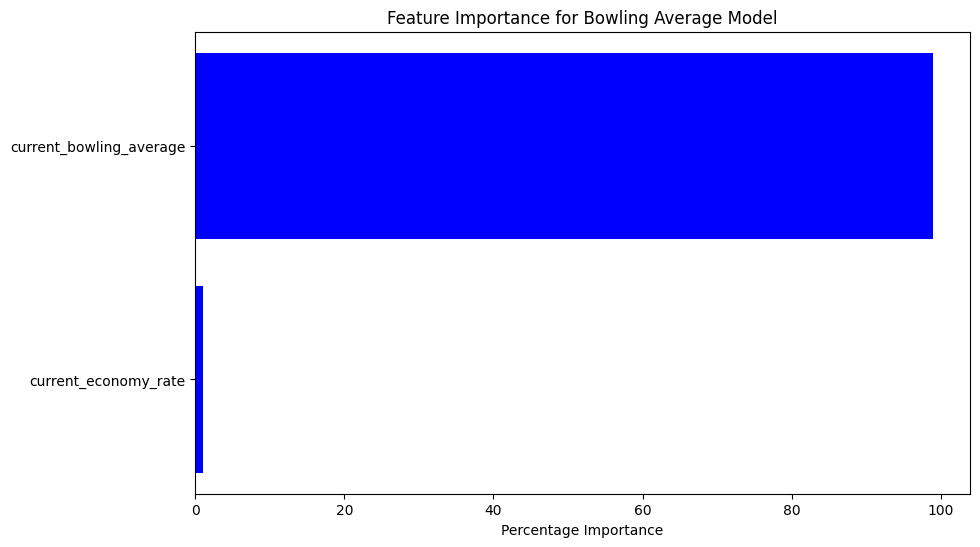

In [44]:
import matplotlib.pyplot as plt
import numpy as np

def plot_importance(model, feature_names, title):
    # Get feature importance
    importance = model.feature_importances_

    # Convert to percentage
    importance = 100.0 * (importance / importance.sum())

    # Sort feature importances in descending order
    indices = np.argsort(importance)[::-1]

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.title(title)
    plt.barh(range(len(indices)), importance[indices], color="b", align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Percentage Importance')
    plt.gca().invert_yaxis()  # To display the most important feature at the top
    plt.show()

# Example of using this function for each model
print("\nEvaluating Batsman Models:")

# For Runs Model
model_runs = XGBRegressor(**xgb_params)
model_runs.fit(X_train_batsman_imputed, y_train_runs)
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
evaluate(y_test_runs, y_pred_runs, "Runs")
plot_importance(model_runs, X_batsman.columns, "Feature Importance for Runs Model")

# For Strike Rate Model
model_strike_rate = XGBRegressor(**xgb_params)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_importance(model_strike_rate, X_batsman.columns, "Feature Importance for Strike Rate Model")

# For Average Model
model_average = XGBRegressor(**xgb_params)
model_average.fit(X_train_batsman_imputed, y_train_average)
y_pred_average = model_average.predict(X_test_batsman_imputed)
evaluate(y_test_average, y_pred_average, "Average")
plot_importance(model_average, X_batsman.columns, "Feature Importance for Average Model")

print("\nEvaluating Bowler Models:")

# For Economy Rate Model
model_economy_rate = XGBRegressor(**xgb_params)
model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_importance(model_economy_rate, X_bowler.columns, "Feature Importance for Economy Rate Model")

# For Wickets Model
model_wickets = XGBRegressor(**xgb_params)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
evaluate(y_test_wickets, y_pred_wickets, "Wickets")
plot_importance(model_wickets, X_bowler.columns, "Feature Importance for Wickets Model")

# For Bowling Average Model
model_bowling_average = XGBRegressor(**xgb_params)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")
plot_importance(model_bowling_average, X_bowler.columns, "Feature Importance for Bowling Average Model")



Evaluating Batsman Models:
Runs - MAE: 4.0010, MSE: 123.3088, R²: 0.9996


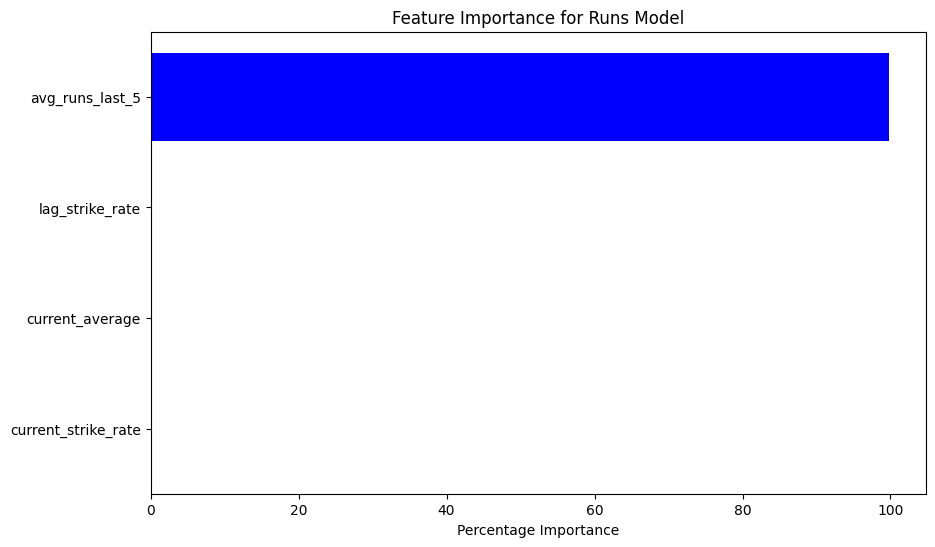

Strike Rate - MAE: 1.1603, MSE: 12.4134, R²: 0.9876


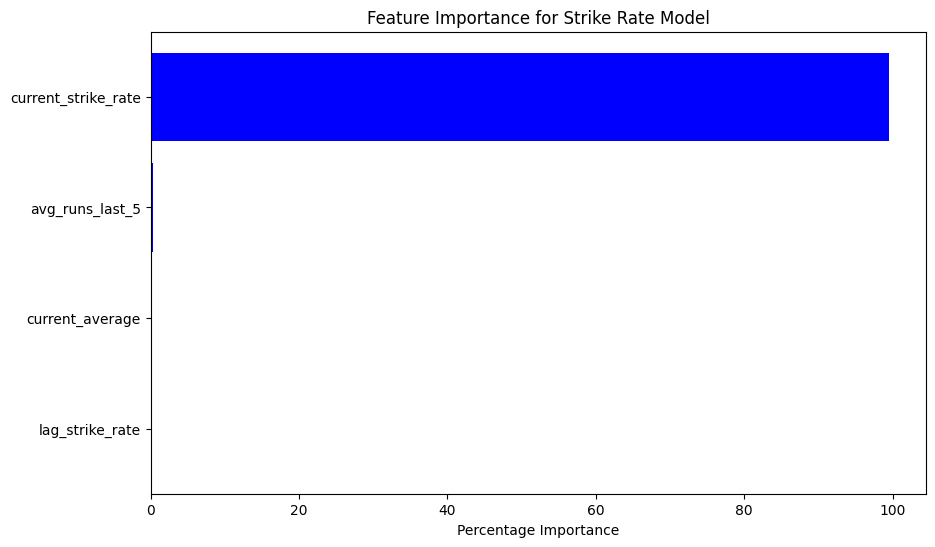

Average - MAE: 0.5381, MSE: 5.4933, R²: 0.9704


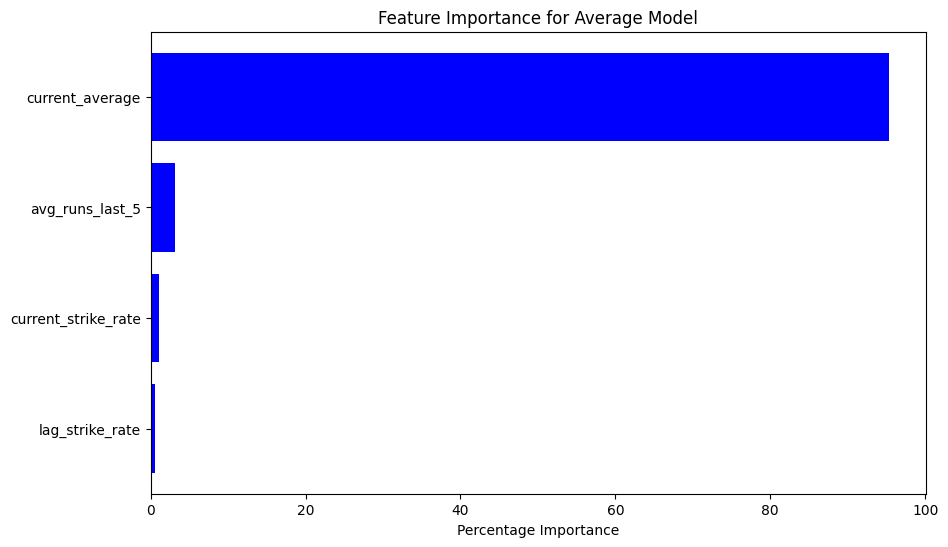


Evaluating Bowler Models:
Economy Rate - MAE: 0.2144, MSE: 0.2071, R²: 0.9597


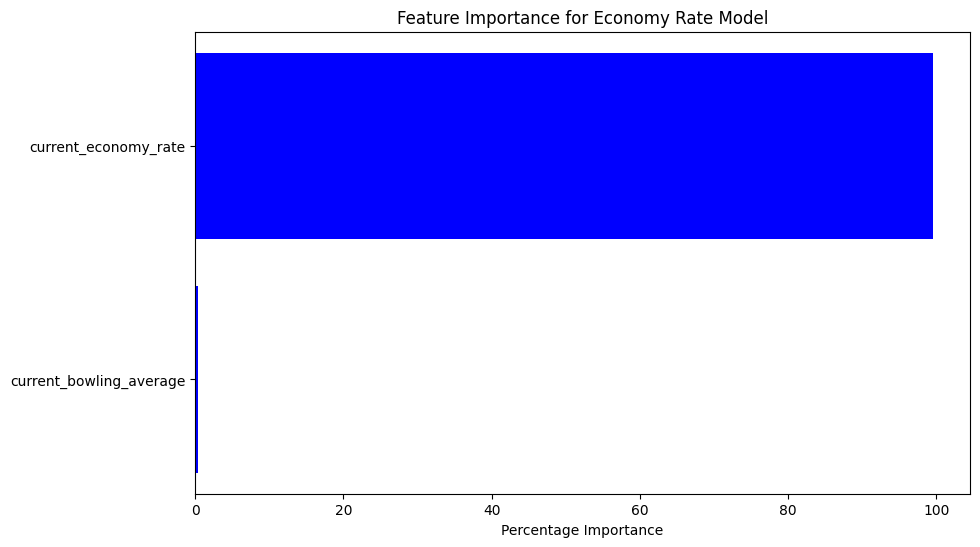

Wickets - MAE: 1.9425, MSE: 9.0533, R²: 0.3182


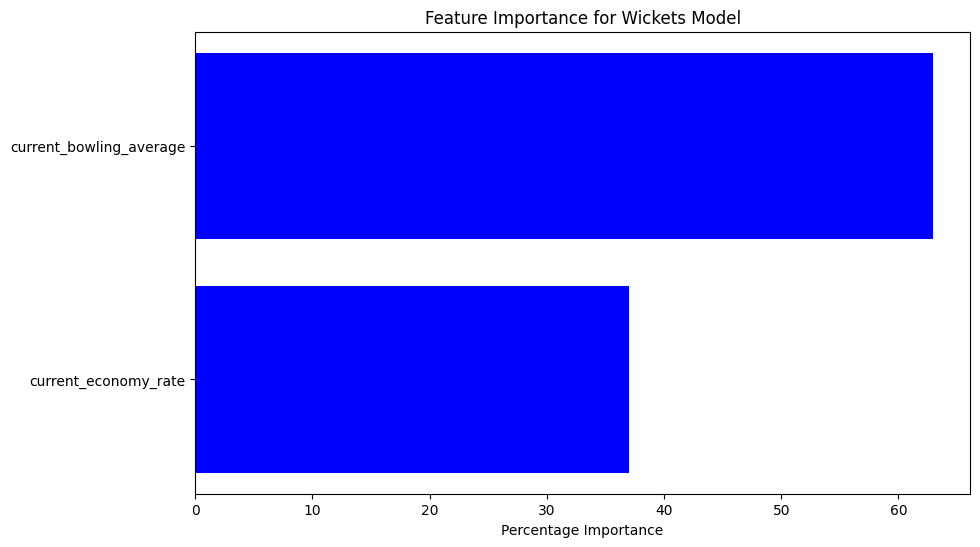

Bowling Average - MAE: 1.1714, MSE: 12.1225, R²: 0.9551


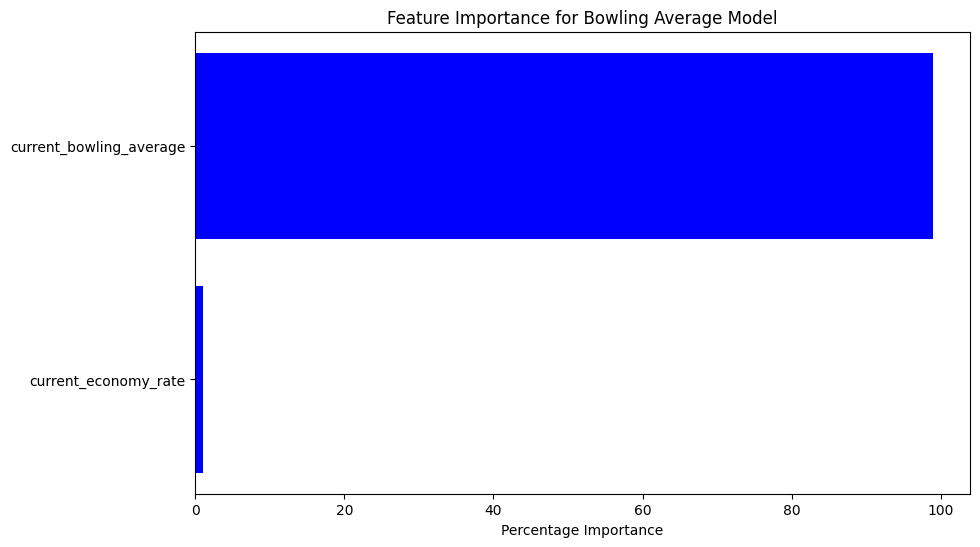

In [47]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor, plot_importance
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process data
def process_data(df):
    df.reset_index(drop=True, inplace=True)
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)
    df = df.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    df = df.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    df = df.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Create Bowling_Team column
    df['Bowling_Team'] = df['Batting_Team'].shift(-1)
    df.loc[df['Inning_Number'] % 2 == 1, 'Bowling_Team'] = df['Batting_Team']

    df['balls_faced'] = df.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    df['total_runs'] = df.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    df['dismissals'] = (df['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    df['cumulative_dismissals'] = df.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()
    df['current_strike_rate'] = (df['total_runs'] / df['balls_faced']) * 100
    df['current_average'] = df['total_runs'] / df['cumulative_dismissals'].replace(0, np.nan)
    df['balls_bowled'] = df.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    df['total_runs_conceded'] = df.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    df['total_wickets'] = df.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()
    df['current_economy_rate'] = (df['total_runs_conceded'] / df['balls_bowled']) * 6
    df['current_bowling_average'] = df['total_runs_conceded'] / df['total_wickets'].replace(0, np.nan)
    return df

# Load and process the entire dataset directly
df = pd.read_csv('final_combined.csv', index_col=0)
processed_df = process_data(df)

# Ensure features are computed based on historical data up to the last match
processed_df = processed_df.sort_values(['Batsman', 'date']).reset_index(drop=True)

# Create historical averages and lag features
processed_df['avg_runs_last_5'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].transform(lambda x: x.rolling(5, min_periods=1).mean())
processed_df['lag_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(1)

# Add overall historical performance against the opponent team (e.g., average runs, strike rate)
def historical_performance_against_team(df, client_team, opponent_team):
    df_client = df[df['Batting_Team'] == client_team]
    df_opponent = df[(df['Batting_Team'] == client_team) & (df['Bowling_Team'] == opponent_team)].copy()

    # Compute historical averages against the opponent team
    df_opponent['avg_runs_against_opponent'] = df_opponent.groupby(['Batsman', 'Bowling_Team'])['total_runs'].transform('mean')
    df_opponent['strike_rate_against_opponent'] = df_opponent.groupby(['Batsman', 'Bowling_Team'])['current_strike_rate'].transform('mean')

    # Fill with zero if never played against the opponent
    df_opponent['avg_runs_against_opponent'].fillna(0, inplace=True)
    df_opponent['strike_rate_against_opponent'].fillna(0, inplace=True)

    return df_opponent

client_team = "India"
opponent_team = "Australia"
processed_df = historical_performance_against_team(processed_df, client_team, opponent_team)

# Remove potentially problematic features
processed_df = processed_df.drop(columns=['venue'])

# Create target variables for the next match performance
processed_df['next_match_total_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_current_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_current_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

# Check if target columns are properly populated
if processed_df[['next_match_total_runs', 'next_match_current_strike_rate', 'next_match_current_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets']].isnull().all().all():
    raise ValueError("Target columns have not been populated correctly. Please check the preprocessing steps.")

# Drop rows with NaN in target columns
processed_df.dropna(subset=['next_match_total_runs', 'next_match_current_strike_rate', 'next_match_current_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Features and target variables
X_batsman = processed_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate', 'avg_runs_against_opponent', 'strike_rate_against_opponent']]
y_runs = processed_df['next_match_total_runs']
y_strike_rate = processed_df['next_match_current_strike_rate']
y_average = processed_df['next_match_current_average']

X_bowler = processed_df[['current_economy_rate', 'current_bowling_average']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# General train-test split
if len(X_batsman) > 0 and len(X_bowler) > 0:
    X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
    _, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
    _, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

    X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
    _, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
    _, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

    # Impute missing values
    imputer = SimpleImputer(strategy='mean')
    X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
    X_test_batsman_imputed = imputer.transform(X_test_batsman)

    X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
    X_test_bowler_imputed = imputer.transform(X_test_bowler)

    # Function to evaluate models
    def evaluate(y_true, y_pred, name):
        mae = mean_absolute_error(y_true, y_pred)
        mse = mean_squared_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        print(f"{name} - MAE: {mae:.4f}, MSE: {mse:.4f}, R²: {r2:.4f}")
        return mae, mse, r2

    # XGBoost parameters
    xgb_params = {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 6, 'random_state': 42, 'n_jobs': -1}

    # Train and evaluate on general train-test split
    print("\nEvaluating Batsman Models:")
    model_runs = XGBRegressor(**xgb_params)
    model_runs.fit(X_train_batsman_imputed, y_train_runs)
    y_pred_runs = model_runs.predict(X_test_batsman_imputed)
    evaluate(y_test_runs, y_pred_runs, "Runs")
    plot_importance(model_runs, X_batsman.columns, "Feature Importance for Runs Model")

    model_strike_rate = XGBRegressor(**xgb_params)
    model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
    y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
    evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
    plot_importance(model_strike_rate, X_batsman.columns, "Feature Importance for Strike Rate Model")

    model_average = XGBRegressor(**xgb_params)
    model_average.fit(X_train_batsman_imputed, y_train_average)
    y_pred_average = model_average.predict(X_test_batsman_imputed)
    evaluate(y_test_average, y_pred_average, "Average")
    plot_importance(model_average, X_batsman.columns, "Feature Importance for Average Model")

    print("\nEvaluating Bowler Models:")
    model_economy_rate = XGBRegressor(**xgb_params)
    model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
    y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
    evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
    plot_importance(model_economy_rate, X_bowler.columns, "Feature Importance for Economy Rate Model")

    model_wickets = XGBRegressor(**xgb_params)
    model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
    y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
    evaluate(y_test_wickets, y_pred_wickets, "Wickets")
    plot_importance(model_wickets, X_bowler.columns, "Feature Importance for Wickets Model")

    model_bowling_average = XGBRegressor(**xgb_params)
    model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)
    y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)
    evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")
    plot_importance(model_bowling_average, X_bowler.columns, "Feature Importance for Bowling Average Model")

    # Plot predicted vs actual for visual inspection
    def plot_predictions(y_true, y_pred, title):
        plt.figure(figsize=(8, 6))
        plt.scatter(y_true, y_pred, alpha=0.3)
        plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', lw=2)
        plt.xlabel('Actual')
        plt.ylabel('Predicted')
        plt.title(f'Predicted vs Actual {title}')
        plt.show()

    # Plot results for batsman models
    print("\nPlotting Batsman Models:")
    plot_predictions(y_test_runs, y_pred_runs, "Runs")
    plot_predictions(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
    plot_predictions(y_test_average, y_pred_average, "Average")

    # Plot results for bowler models
    print("\nPlotting Bowler Models:")
    plot_predictions(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
    plot_predictions(y_test_wickets, y_pred_wickets, "Wickets")
    plot_predictions(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")

    # Now, let's move to the scenario testing part with imputation and testing.

    # Function to create test sets for scenarios
    def create_scenario_test_sets(processed_df, client_team, opponent_team=None):
        # Scenario 1: Last match of the client team against any opponent
        scenario_1 = processed_df[processed_df['Batting_Team'] == client_team].sort_values('date', ascending=False).groupby('Batsman').first().reset_index()

        # Scenario 2: Last match of the client team against the specified opponent
        if opponent_team:
            scenario_2 = processed_df[(processed_df['Batting_Team'] == client_team) & (processed_df['Bowling_Team'] == opponent_team)].sort_values('date', ascending=False).groupby('Batsman').first().reset_index()
        else:
            scenario_2 = pd.DataFrame()

        return scenario_1, scenario_2

    # Example of using the function with "India" as the client team and "Australia" as the opponent
    client_team = "India"
    opponent_team = "Australia"
    scenario_1_df, scenario_2_df = create_scenario_test_sets(processed_df, client_team, opponent_team)

    # Impute missing values in test sets
    def impute_missing_values(X_test):
        imputer = SimpleImputer(strategy='mean')
        return imputer.fit_transform(X_test)

    # Separate features and targets for scenario 1 and 2
    X_test_batsman_scenario_1 = scenario_1_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]
    X_test_batsman_scenario_2 = scenario_2_df[['current_strike_rate', 'current_average', 'avg_runs_last_5', 'lag_strike_rate']]

    X_test_batsman_scenario_1_imputed = impute_missing_values(X_test_batsman_scenario_1)
    X_test_batsman_scenario_2_imputed = impute_missing_values(X_test_batsman_scenario_2)

    # Scenario 1 Predictions
    y_pred_runs_scenario_1 = model_runs.predict(X_test_batsman_scenario_1_imputed)
    y_pred_strike_rate_scenario_1 = model_strike_rate.predict(X_test_batsman_scenario_1_imputed)
    y_pred_average_scenario_1 = model_average.predict(X_test_batsman_scenario_1_imputed)

    # Scenario 2 Predictions
    y_pred_runs_scenario_2 = model_runs.predict(X_test_batsman_scenario_2_imputed)
    y_pred_strike_rate_scenario_2 = model_strike_rate.predict(X_test_batsman_scenario_2_imputed)
    y_pred_average_scenario_2 = model_average.predict(X_test_batsman_scenario_2_imputed)

    # Evaluate Scenario 1
    print("Scenario 1 Evaluation:")
    evaluate(scenario_1_df['next_match_total_runs'], y_pred_runs_scenario_1, "Runs")
    evaluate(scenario_1_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
    evaluate(scenario_1_df['next_match_current_average'], y_pred_average_scenario_1, "Average")

    # Evaluate Scenario 2
    print("Scenario 2 Evaluation:")
    if not scenario_2_df.empty:
        evaluate(scenario_2_df['next_match_total_runs'], y_pred_runs_scenario_2, "Runs")
        evaluate(scenario_2_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
        evaluate(scenario_2_df['next_match_current_average'], y_pred_average_scenario_2, "Average")

    # Plot Scenario 1
    print("Scenario 1 - Predicted vs Actual Plots:")
    # Plot Scenario 1 - Predicted vs Actual
    print("Scenario 1 - Predicted vs Actual Plots:")
    plot_predictions(scenario_1_df['next_match_total_runs'], y_pred_runs_scenario_1, "Runs")
    plot_predictions(scenario_1_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_1, "Strike Rate")
    plot_predictions(scenario_1_df['next_match_current_average'], y_pred_average_scenario_1, "Average")

    # Plot Scenario 2 - Predicted vs Actual
    if not scenario_2_df.empty:
        print("Scenario 2 - Predicted vs Actual Plots:")
        plot_predictions(scenario_2_df['next_match_total_runs'], y_pred_runs_scenario_2, "Runs")
        plot_predictions(scenario_2_df['next_match_current_strike_rate'], y_pred_strike_rate_scenario_2, "Strike Rate")
        plot_predictions(scenario_2_df['next_match_current_average'], y_pred_average_scenario_2, "Average")

def plot_importance(model, feature_names, title):
    # Get feature importance
    importance = model.feature_importances_

    # Convert to percentage
    importance = 100.0 * (importance / importance.sum())

    # Sort feature importances in descending order
    indices = np.argsort(importance)[::-1]

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.title(title)
    plt.barh(range(len(indices)), importance[indices], color="b", align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Percentage Importance')
    plt.gca().invert_yaxis()  # To display the most important feature at the top
    plt.show()

# Example of using this function for each model
print("\nEvaluating Batsman Models:")

# For Runs Model
model_runs = XGBRegressor(**xgb_params)
model_runs.fit(X_train_batsman_imputed, y_train_runs)
y_pred_runs = model_runs.predict(X_test_batsman_imputed)
evaluate(y_test_runs, y_pred_runs, "Runs")
plot_importance(model_runs, X_batsman.columns, "Feature Importance for Runs Model")

# For Strike Rate Model
model_strike_rate = XGBRegressor(**xgb_params)
model_strike_rate.fit(X_train_batsman_imputed, y_train_strike_rate)
y_pred_strike_rate = model_strike_rate.predict(X_test_batsman_imputed)
evaluate(y_test_strike_rate, y_pred_strike_rate, "Strike Rate")
plot_importance(model_strike_rate, X_batsman.columns, "Feature Importance for Strike Rate Model")

# For Average Model
model_average = XGBRegressor(**xgb_params)
model_average.fit(X_train_batsman_imputed, y_train_average)
y_pred_average = model_average.predict(X_test_batsman_imputed)
evaluate(y_test_average, y_pred_average, "Average")
plot_importance(model_average, X_batsman.columns, "Feature Importance for Average Model")

print("\nEvaluating Bowler Models:")

# For Economy Rate Model
model_economy_rate = XGBRegressor(**xgb_params)
model_economy_rate.fit(X_train_bowler_imputed, y_train_economy_rate)
y_pred_economy_rate = model_economy_rate.predict(X_test_bowler_imputed)
evaluate(y_test_economy_rate, y_pred_economy_rate, "Economy Rate")
plot_importance(model_economy_rate, X_bowler.columns, "Feature Importance for Economy Rate Model")

# For Wickets Model
model_wickets = XGBRegressor(**xgb_params)
model_wickets.fit(X_train_bowler_imputed, y_train_wickets)
y_pred_wickets = model_wickets.predict(X_test_bowler_imputed)
evaluate(y_test_wickets, y_pred_wickets, "Wickets")
plot_importance(model_wickets, X_bowler.columns, "Feature Importance for Wickets Model")

# For Bowling Average Model
model_bowling_average = XGBRegressor(**xgb_params)
model_bowling_average.fit(X_train_bowler_imputed, y_train_bowling_average)
y_pred_bowling_average = model_bowling_average.predict(X_test_bowler_imputed)
evaluate(y_test_bowling_average, y_pred_bowling_average, "Bowling Average")
plot_importance(model_bowling_average, X_bowler.columns, "Feature Importance for Bowling Average Model")




In [54]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor, plot_importance
import matplotlib.pyplot as plt

# Load player info
player_info = pd.read_excel('Formatted_Full_playerinfo.com (2).xlsx')
batting_type = player_info[['Player Name', 'Batting type']].set_index('Player Name')
bowling_type = player_info[['Player Name', 'Bowling type']].set_index('Player Name')
playing_role = player_info[['Player Name', 'Playing role']].set_index('Player Name')

# Function to process data
def process_data(df):
    print("Initial columns:", df.columns.tolist())  # Debug: Initial columns
    df.reset_index(drop=True, inplace=True)
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df.fillna({
        'Wides': 0, 'No_Balls': 0, 'Byes': 0, 'Leg_Byes': 0,
        'Kind_of_wicket_If_Any': 'Not Out', 'Dissmissed_Player_When_Wicket': 'Not Out',
    }, inplace=True)

    df = df.merge(batting_type, how='left', left_on='Batsman', right_index=True)
    df = df.merge(bowling_type, how='left', left_on='Bowler', right_index=True)
    df = df.merge(playing_role, how='left', left_on='Batsman', right_index=True)

    # Create Bowling_Team column
    df['Bowling_Team'] = df['Batting_Team'].shift(-1)
    df.loc[df['Inning_Number'] % 2 == 1, 'Bowling_Team'] = df['Batting_Team']

    # Ensure the 'total_runs' column is properly calculated
    df['balls_faced'] = df.groupby(['Batsman', 'Batting_Team']).cumcount() + 1
    df['total_runs'] = df.groupby(['Batsman', 'Batting_Team'])['Runs_off_Bat'].cumsum()
    df['dismissals'] = (df['Dissmissed_Player_When_Wicket'] != 'Not Out').astype(int)
    df['cumulative_dismissals'] = df.groupby(['Batsman', 'Batting_Team'])['dismissals'].cumsum()

    print("Columns after basic processing:", df.columns.tolist())  # Debug: Columns after basic processing

    # For bowlers
    df['balls_bowled'] = df.groupby(['Bowler', 'Bowling_Team']).cumcount() + 1
    df['total_runs_conceded'] = df.groupby(['Bowler', 'Bowling_Team'])['Runs_off_Bat'].cumsum()
    df['total_wickets'] = df.groupby(['Bowler', 'Bowling_Team'])['dismissals'].cumsum()

    # Calculate current strike rate and current average
    df['current_strike_rate'] = (df['total_runs'] / df['balls_faced']) * 100
    df['current_average'] = df['total_runs'] / df['cumulative_dismissals'].replace(0, np.nan)
    df['current_economy_rate'] = (df['total_runs_conceded'] / df['balls_bowled']) * 6
    df['current_bowling_average'] = df['total_runs_conceded'] / df['total_wickets'].replace(0, np.nan)

    print("Columns after calculating derived metrics:", df.columns.tolist())  # Debug: Columns after derived metrics

    return df

# Load and process the entire dataset directly
df = pd.read_csv('final_combined.csv', index_col=0)
processed_df = process_data(df)

# Now, creating the target variables for the next match performance
print("Creating target variables...")
processed_df['next_match_total_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(-1)
processed_df['next_match_current_strike_rate'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_strike_rate'].shift(-1)
processed_df['next_match_current_average'] = processed_df.groupby(['Batsman', 'Batting_Team'])['current_average'].shift(-1)
processed_df['next_match_economy_rate'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_economy_rate'].shift(-1)
processed_df['next_match_average_bowling'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['current_bowling_average'].shift(-1)
processed_df['next_match_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(-1)

print("Target variables created successfully.")

# Drop rows with NaN in target columns to ensure clean data
processed_df.dropna(subset=['next_match_total_runs', 'next_match_current_strike_rate', 'next_match_current_average', 'next_match_economy_rate', 'next_match_average_bowling', 'next_match_wickets'], inplace=True)

# Continue with feature engineering: Creating rolling averages and lag features
processed_df['avg_runs_last_5'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].transform(lambda x: x.rolling(5, min_periods=1).mean())
processed_df['lag_total_runs'] = processed_df.groupby(['Batsman', 'Batting_Team'])['total_runs'].shift(1)
processed_df['lag_dismissals'] = processed_df.groupby(['Batsman', 'Batting_Team'])['dismissals'].shift(1)

# For bowlers, create lag features
processed_df['lag_runs_conceded'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_runs_conceded'].shift(1)
processed_df['lag_wickets'] = processed_df.groupby(['Bowler', 'Bowling_Team'])['total_wickets'].shift(1)

# Drop rows with NaN in lagged columns
processed_df.dropna(inplace=True)

print("Feature engineering complete. Available columns:", processed_df.columns.tolist())  # Debug: Final columns after feature engineering

# Features and target variables for batsmen
X_batsman = processed_df[['avg_runs_last_5', 'lag_total_runs', 'lag_dismissals']]
y_runs = processed_df['next_match_total_runs']

# Features and target variables for bowlers
X_bowler = processed_df[['lag_runs_conceded', 'lag_wickets']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

# Continue with training, testing, and evaluation as before...


Initial columns: ['Inning_Number', 'Over.Ball', 'Batting_Team', 'Batsman', 'Non_Stricker', 'Bowler', 'Runs_off_Bat', 'Extras', 'Wides', 'No_Balls', 'Byes', 'Leg_Byes', 'Penalty', 'Kind_of_wicket_If_Any', 'Dissmissed_Player_When_Wicket', 'city', 'gender', 'date', 'toss_winner', 'toss_decision', 'venue', 'match_id']
Columns after basic processing: ['Inning_Number', 'Over.Ball', 'Batting_Team', 'Batsman', 'Non_Stricker', 'Bowler', 'Runs_off_Bat', 'Extras', 'Wides', 'No_Balls', 'Byes', 'Leg_Byes', 'Penalty', 'Kind_of_wicket_If_Any', 'Dissmissed_Player_When_Wicket', 'city', 'gender', 'date', 'toss_winner', 'toss_decision', 'venue', 'match_id', 'Batting type', 'Bowling type', 'Playing role', 'Bowling_Team', 'balls_faced', 'total_runs', 'dismissals', 'cumulative_dismissals']
Columns after calculating derived metrics: ['Inning_Number', 'Over.Ball', 'Batting_Team', 'Batsman', 'Non_Stricker', 'Bowler', 'Runs_off_Bat', 'Extras', 'Wides', 'No_Balls', 'Byes', 'Leg_Byes', 'Penalty', 'Kind_of_wicket_

In [56]:
# Exclude current performance metrics from the features to prevent data leakage
print("Features available before exclusion:")
print(processed_df.columns)

X_batsman = processed_df[['avg_runs_last_5', 'lag_total_runs', 'lag_dismissals']]
y_runs = processed_df['next_match_total_runs']
y_strike_rate = processed_df['next_match_current_strike_rate']
y_average = processed_df['next_match_current_average']

X_bowler = processed_df[['lag_runs_conceded', 'lag_wickets']]
y_economy_rate = processed_df['next_match_economy_rate']
y_wickets = processed_df['next_match_wickets']
y_bowling_average = processed_df['next_match_average_bowling']

print("Shapes of dataframes before splitting:")
print(f"X_batsman shape: {X_batsman.shape}")
print(f"y_runs shape: {y_runs.shape}")
print(f"y_strike_rate shape: {y_strike_rate.shape}")
print(f"y_average shape: {y_average.shape}")
print(f"X_bowler shape: {X_bowler.shape}")
print(f"y_economy_rate shape: {y_economy_rate.shape}")
print(f"y_wickets shape: {y_wickets.shape}")
print(f"y_bowling_average shape: {y_bowling_average.shape}")

# General train-test split
X_train_batsman, X_test_batsman, y_train_runs, y_test_runs = train_test_split(X_batsman, y_runs, test_size=0.2, random_state=42)
_, _, y_train_strike_rate, y_test_strike_rate = train_test_split(X_batsman, y_strike_rate, test_size=0.2, random_state=42)
_, _, y_train_average, y_test_average = train_test_split(X_batsman, y_average, test_size=0.2, random_state=42)

X_train_bowler, X_test_bowler, y_train_economy_rate, y_test_economy_rate = train_test_split(X_bowler, y_economy_rate, test_size=0.2, random_state=42)
_, _, y_train_wickets, y_test_wickets = train_test_split(X_bowler, y_wickets, test_size=0.2, random_state=42)
_, _, y_train_bowling_average, y_test_bowling_average = train_test_split(X_bowler, y_bowling_average, test_size=0.2, random_state=42)

print("Shapes of train/test splits:")
print(f"X_train_batsman shape: {X_train_batsman.shape}, X_test_batsman shape: {X_test_batsman.shape}")
print(f"y_train_runs shape: {y_train_runs.shape}, y_test_runs shape: {y_test_runs.shape}")
print(f"y_train_strike_rate shape: {y_train_strike_rate.shape}, y_test_strike_rate shape: {y_test_strike_rate.shape}")
print(f"y_train_average shape: {y_train_average.shape}, y_test_average shape: {y_test_average.shape}")
print(f"X_train_bowler shape: {X_train_bowler.shape}, X_test_bowler shape: {X_test_bowler.shape}")
print(f"y_train_economy_rate shape: {y_train_economy_rate.shape}, y_test_economy_rate shape: {y_test_economy_rate.shape}")
print(f"y_train_wickets shape: {y_train_wickets.shape}, y_test_wickets shape: {y_test_wickets.shape}")
print(f"y_train_bowling_average shape: {y_train_bowling_average.shape}, y_test_bowling_average shape: {y_test_bowling_average.shape}")

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_train_batsman_imputed = imputer.fit_transform(X_train_batsman)
X_test_batsman_imputed = imputer.transform(X_test_batsman)

X_train_bowler_imputed = imputer.fit_transform(X_train_bowler)
X_test_bowler_imputed = imputer.transform(X_test_bowler)

# Continue with the rest of the code for model training and evaluation...


Features available before exclusion:
Index(['Inning_Number', 'Over.Ball', 'Batting_Team', 'Batsman', 'Non_Stricker',
       'Bowler', 'Runs_off_Bat', 'Extras', 'Wides', 'No_Balls', 'Byes',
       'Leg_Byes', 'Penalty', 'Kind_of_wicket_If_Any',
       'Dissmissed_Player_When_Wicket', 'city', 'gender', 'date',
       'toss_winner', 'toss_decision', 'venue', 'match_id', 'Batting type',
       'Bowling type', 'Playing role', 'Bowling_Team', 'balls_faced',
       'total_runs', 'dismissals', 'cumulative_dismissals', 'balls_bowled',
       'total_runs_conceded', 'total_wickets', 'current_strike_rate',
       'current_average', 'current_economy_rate', 'current_bowling_average',
       'next_match_total_runs', 'next_match_current_strike_rate',
       'next_match_current_average', 'next_match_economy_rate',
       'next_match_average_bowling', 'next_match_wickets', 'avg_runs_last_5',
       'lag_total_runs', 'lag_dismissals', 'lag_runs_conceded', 'lag_wickets'],
      dtype='object')
Shapes of d

ValueError: With n_samples=1, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.